# Dietary bioactives and the shared transcriptomic signature of allergic disease

**Computing Bioinformatics – Group Project**

This notebook runs top-to-bottom in Google Colab (or locally). Every number,
table and figure below is produced by the code in this notebook from public data.

## Stage 1 – Research question, objectives and hypotheses

**Biological problem.** Allergic diseases (allergic rhinitis, asthma, chronic
rhinosinusitis with nasal polyps, atopic dermatitis, eosinophilic oesophagitis)
affect different organs but share type-2 inflammation and epithelial-barrier
dysfunction. Many food-derived compounds (flavonoids such as quercetin, curcumin,
resveratrol, omega-3 fatty acids, vitamin D, …) are marketed or studied as
"anti-allergic". Whether their known molecular targets actually overlap the genes
that are dysregulated in allergic tissue – and whether they push those genes in the
*opposite* direction to disease – is rarely tested systematically or against a
fair baseline.

**Research question.** *Are the genes that are consistently dysregulated across human
allergic tissues over-represented among the curated gene targets of common dietary
bioactive compounds, beyond what is expected from how well-studied those genes are,
and do these compounds tend to shift their targets' expression in the direction
opposite to disease?*

**Objectives**

1. **O1 – Allergy signature.** Derive differential-expression signatures (allergic vs
   healthy, FDR-controlled) in 7 public transcriptomic comparisons covering nose,
   bronchus, sinus, skin and oesophagus, and combine them into a consensus
   cross-tissue allergy signature.
2. **O2 – Bioactive target enrichment and direction.** Test whether curated human
   targets (CTD) of a panel of dietary bioactives are enriched in that signature,
   using a degree-matched null and a comparison against all other CTD chemicals, and
   test whether their reported effects oppose the disease direction ("reversal").
3. **O3 – Biological interpretation.** Interpret the signature and the
   bioactive-reversible genes with Reactome pathway enrichment, CTD curated
   gene–disease evidence and a compound–gene network (NetworkX).
4. **O4 – Prediction.** Test whether expression of bioactive-target genes classifies
   allergic vs healthy samples, within and across datasets, against proper
   baselines (majority class, random gene sets of equal size, all genes).

**Hypotheses**

* **H1:** the consensus allergy signature is enriched for dietary-bioactive targets
  after correcting for gene "study bias" (degree-matched null; FDR < 0.05).
* **H2:** dietary bioactives are *more* enriched than typical non-dietary CTD
  chemicals (one-sided Mann–Whitney).
* **H3:** for signature genes, bioactive-induced expression changes are more often
  opposite to the disease direction than same-direction (> 50 %, and more than
  non-dietary chemicals).
* **H4:** bioactive-target genes classify disease status better than a majority
  baseline and at least as well as random gene sets of the same size.

Null hypotheses are the negations; we report every result whether or not it
supports the hypothesis.

### Setup
In Colab this cell clones the repository and downloads the raw data (≈110 MB,
2–4 minutes). Locally it uses the repository you are in.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/NICKMUGO/DietaryBioactivesAndAllergy.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not Path("DietaryBioactivesAndAllergy").exists():
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir("DietaryBioactivesAndAllergy")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "networkx", "statsmodels"], check=True)

ROOT = Path.cwd()
if not (ROOT / "scripts" / "download_data.py").exists():
    ROOT = ROOT.parent
subprocess.run([sys.executable, str(ROOT / "scripts" / "download_data.py")], check=True)

RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
RES = ROOT / "results"
FIG = RES / "figures"
for d in (PROC, RES, FIG):
    d.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

  skip (exists) data/raw/geo/GSE19187_series_matrix.txt.gz
  skip (exists) data/raw/geo/GSE36830_series_matrix.txt.gz
  skip (exists) data/raw/geo/GSE136825_genecounts.txt.gz
  skip (exists) data/raw/geo/GSE136825_series_matrix.txt.gz
  skip (exists) data/raw/geo/GSE41861_series_matrix.txt.gz
  skip (exists) data/raw/geo/GSE32924_series_matrix.txt.gz
  skip (exists) data/raw/geo/GSE58640_RNAseq_processed.txt.gz
  skip (exists) data/raw/geo/GSE58640_series_matrix.txt.gz
  skip (exists) data/raw/geo/GPL570.annot.gz
  skip (exists) data/raw/geo/GPL6244.annot.gz
  skip (exists) data/raw/ctd/CTD_chem_gene_ixns.tsv.gz
  skip (exists) data/raw/ctd/CTD_chemicals.tsv.gz
  skip (exists) data/raw/ctd/CTD_curated_genes_diseases.tsv.gz
  skip (exists) data/raw/hgnc/hgnc_complete_set.txt
  skip (exists) data/raw/reactome/ReactomePathways.gmt.zip
  skip (exists) data/raw/reactome/ReactomePathwaysRelation.txt

All downloads complete.
project root: /home/mugo/Projects/DietaryBioactivesAndAllergy


In [2]:
import gzip, io, json, re, zipfile, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy import stats, special
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
rng = np.random.default_rng(SEED)

C_CTRL, C_DIS, C_AQUA, C_YEL, C_VIOLET = "#2a78d6", "#e34948", "#1baf7a", "#eda100", "#6250d6"
C_ORANGE, C_MUTED, C_GRID, C_INK = "#eb6834", "#898781", "#e1e0d9", "#0b0b0b"
DIVERGING = matplotlib.colors.LinearSegmentedColormap.from_list(
    "bluegrayred", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a32a2a"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.size": 9, "axes.titlesize": 10,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.grid": True,
    "grid.color": C_GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#52514e",
    "legend.frameon": False,
})

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

DASH = {}

## Stage 2 – Data acquisition

All data are public and downloaded by `scripts/download_data.py` (source URLs are
listed there). Nothing is edited by hand.

| File | Source | What it is | Used for |
|---|---|---|---|
| `GSE19187_series_matrix.txt.gz` | NCBI GEO | Affymetrix HuGene 1.0 ST (GPL6244), RMA log2; nasal epithelium of 38 children: healthy, allergic rhinitis, rhinitis + controlled / uncontrolled asthma | contrast **AR/asthma vs healthy (nasal, child)** |
| `GSE41861_series_matrix.txt.gz` | NCBI GEO | Affymetrix HG-U133 Plus 2 (GPL570), log2; nasal (57) and bronchial (81) brushings, asthma vs control adults | contrasts **asthma vs control (nasal)** and **(bronchial)** |
| `GSE36830_series_matrix.txt.gz` | NCBI GEO | GPL570, log2; uncinate tissue of controls and nasal polyps of CRSwNP patients | contrast **CRSwNP polyp vs control (array)** |
| `GSE136825_genecounts.txt.gz` + series matrix | NCBI GEO | RNA-seq (HiSeq 4000) raw featureCounts, GENCODE v26 Ensembl IDs; 42 polyps, 33 polyp-patient turbinates, 28 control turbinates | contrast **CRSwNP polyp vs control (RNA-seq)** |
| `GSE32924_series_matrix.txt.gz` | NCBI GEO | GPL570, log2; skin of atopic dermatitis (lesional, non-lesional) and healthy volunteers | contrast **AD lesional vs normal skin** |
| `GSE58640_RNAseq_processed.txt.gz` + series matrix | NCBI GEO | RNA-seq FPKM (gene symbols); oesophageal biopsies, active EoE vs healthy | contrast **EoE vs control** |
| `GPL570.annot.gz`, `GPL6244.annot.gz` | NCBI GEO | platform annotation: probe → gene symbol / Entrez ID | probe-to-gene mapping |
| `hgnc_complete_set.txt` | HGNC | approved symbols with Ensembl / Entrez IDs, locus group | Ensembl → symbol for GSE136825 |
| `CTD_chem_gene_ixns.tsv.gz` | Comparative Toxicogenomics Database | curated chemical–gene interactions with action types (e.g. `decreases^expression`) and PubMed IDs | bioactive target sets and directions |
| `CTD_chemicals.tsv.gz` | CTD | chemical vocabulary (MeSH IDs, synonyms) | chemical annotation |
| `CTD_curated_genes_diseases.tsv.gz` | CTD | curated gene–disease associations (marker/mechanism, therapeutic) | external validation of the signature |
| `ReactomePathways.gmt.zip`, `ReactomePathwaysRelation.txt` | Reactome | pathway → gene sets; pathway hierarchy | pathway enrichment |

In [3]:
def read_series_matrix(path):
    meta_rows, table, in_table = defaultdict(list), [], False
    with gzip.open(path, "rt", errors="replace") as fh:
        for line in fh:
            if line.startswith("!series_matrix_table_begin"):
                in_table = True; continue
            if line.startswith("!series_matrix_table_end"):
                break
            if in_table:
                table.append(line.rstrip("\n").split("\t"))
            elif line.startswith("!Sample_"):
                key, *vals = line.rstrip("\n").split("\t")
                meta_rows[key].append([v.strip('"') for v in vals])
    meta = {}
    for key, rows in meta_rows.items():
        if key == "!Sample_characteristics_ch1":
            for row in rows:
                for i, v in enumerate(row):
                    if ":" in v:
                        k, val = v.split(":", 1)
                        meta.setdefault(k.strip().lower(), [None] * len(row))[i] = val.strip()
        else:
            meta[key.replace("!Sample_", "")] = rows[0]
    meta = pd.DataFrame(meta)
    meta.index = meta["geo_accession"]
    expr = None
    if len(table) > 1:
        header = [h.strip('"') for h in table[0]]
        expr = pd.DataFrame([r[1:] for r in table[1:]], index=[r[0].strip('"') for r in table[1:]],
                            columns=header[1:])
        expr = expr.apply(pd.to_numeric, errors="coerce")
    return expr, meta


def read_platform_annot(path):
    with gzip.open(path, "rt", errors="replace") as fh:
        lines = fh.readlines()
    start = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_begin")) + 1
    end = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_end"))
    ann = pd.read_csv(io.StringIO("".join(lines[start:end])), sep="\t", dtype=str)
    return ann[["ID", "Gene symbol"]].rename(columns={"Gene symbol": "symbol"})

raw = {}
for gse in ["GSE19187", "GSE41861", "GSE36830", "GSE32924", "GSE136825", "GSE58640"]:
    raw[gse] = read_series_matrix(RAW / "geo" / f"{gse}_series_matrix.txt.gz")
    e, m = raw[gse]
    print(f"{gse}: samples={len(m):4d}  expression rows in matrix={0 if e is None else len(e):6d}")

annot = {g: read_platform_annot(RAW / "geo" / f"{g}.annot.gz") for g in ["GPL570", "GPL6244"]}
hgnc = pd.read_csv(RAW / "hgnc" / "hgnc_complete_set.txt", sep="\t", dtype=str,
                   usecols=["symbol", "locus_group", "entrez_id", "ensembl_gene_id"])
gse136825_counts = pd.read_csv(RAW / "geo" / "GSE136825_genecounts.txt.gz", sep="\t")
gse58640_fpkm = pd.read_csv(RAW / "geo" / "GSE58640_RNAseq_processed.txt.gz", sep="\t")
print("GSE136825 counts:", gse136825_counts.shape, " GSE58640 FPKM:", gse58640_fpkm.shape)
print("HGNC genes:", len(hgnc))

GSE19187: samples=  38  expression rows in matrix= 33297


GSE41861: samples= 138  expression rows in matrix= 30427


GSE36830: samples=  24  expression rows in matrix= 54675


GSE32924: samples=  33  expression rows in matrix= 54675
GSE136825: samples= 103  expression rows in matrix=     0
GSE58640: samples=  16  expression rows in matrix=     0


GSE136825 counts: (58219, 109)  GSE58640 FPKM: (31666, 18)
HGNC genes: 45326


**Variables used from the metadata**

* GSE19187 – `disease state` (Healthy / Rhinitis / Rhinitis with controlled asthma / Uncontrolled asthma), `gender`, `age`.
* GSE41861 – `disease` (Asthma / Control), `severity`, `tissue` (Upper airway (Nasal) / Lower airway (bronchial)), `sex`, `age`.
* GSE36830 – `title` (Control UT / CRSsNP UT / CRSwNP UT / CRSwNP polyp).
* GSE136825 – `source_name_ch1` (Nasal Polyp Tissue / Nasal Polyp Inferior Turbinate / Control Inferior Turbinate); `description` links the sample to the count-matrix column (`RHPxxxx.bam`).
* GSE32924 – `condition` (AL = lesional, ANL = non-lesional, Normal), `individual`, `eczema severity` (SCORAD).
* GSE58640 – `patient cohort` (healthy control / active EoE); `title` matches the FPKM column names.

Expression values: microarray series matrices hold log2 RMA intensities per probe; GSE136825 holds
raw integer read counts per Ensembl gene; GSE58640 holds FPKM per gene symbol.

**Design choices that matter.** For each study we keep only independent individuals in the two
groups being compared (e.g. AD *lesional vs normal* rather than lesional vs non-lesional of the same
patient; CRSwNP *polyp vs control turbinate* rather than polyp vs the same patient's turbinate).
CRS without polyps (not type-2 dominated) is excluded. GSE41861 nasal and bronchial samples come
largely from the same people, so those two contrasts are not fully independent – we note this
where it matters.

In [4]:
def collapse_probes(expr, ann):
    a = ann.dropna(subset=["symbol"])
    a = a[~a.symbol.str.contains("///")].set_index("ID")["symbol"]
    e = expr.loc[expr.index.intersection(a.index)].copy()
    e["__sym"] = a.loc[e.index].values
    e["__mean"] = e.drop(columns="__sym").mean(axis=1)
    e = e.sort_values("__mean", ascending=False).drop_duplicates("__sym")
    return e.set_index("__sym").drop(columns="__mean")

datasets = {}

def add_dataset(name, expr, meta, label, tissue, disease, gse, kind):
    keep = label.dropna().index
    datasets[name] = dict(expr_raw=expr[keep], meta=meta.loc[keep], label=label.loc[keep].astype(int),
                          tissue=tissue, disease=disease, gse=gse, kind=kind)

e, m = raw["GSE19187"]
lab = m["disease state"].map(lambda s: 0 if s == "Healthy" else 1)
add_dataset("AR/asthma nasal (child)", collapse_probes(e, annot["GPL6244"]), m, lab,
            "nasal epithelium", "allergic rhinitis ± asthma", "GSE19187", "array")

e, m = raw["GSE41861"]
ge = collapse_probes(e, annot["GPL570"])
lab = m["disease"].map({"Asthma": 1, "Control": 0})
for tis, nm in [("Upper airway (Nasal)", "Asthma nasal"), ("Lower airway (bronchial)", "Asthma bronchial")]:
    idx = m.index[m["tissue"] == tis]
    add_dataset(nm, ge[idx], m.loc[idx], lab.loc[idx],
                "nasal epithelium" if "Nasal" in tis else "bronchial epithelium", "asthma", "GSE41861", "array")

e, m = raw["GSE36830"]
lab = m["title"].map(lambda t: 0 if t.startswith("Control") else (1 if "polyp" in t else np.nan))
add_dataset("CRSwNP polyp (array)", collapse_probes(e, annot["GPL570"]), m, lab,
            "sinonasal tissue", "chronic rhinosinusitis with nasal polyps", "GSE36830", "array")

e, m = raw["GSE32924"]
lab = m["condition"].map({"AL": 1, "Normal": 0})
add_dataset("Atopic dermatitis skin", collapse_probes(e, annot["GPL570"]), m, lab,
            "skin", "atopic dermatitis", "GSE32924", "array")

_, m = raw["GSE136825"]
cnt = gse136825_counts.copy()
cnt["ens"] = cnt["Geneid"].str.split(".").str[0]
ens2sym = (hgnc.dropna(subset=["ensembl_gene_id"]).drop_duplicates("ensembl_gene_id")
           .set_index("ensembl_gene_id")["symbol"])
cnt = cnt[cnt.ens.isin(ens2sym.index)]
cnt["sym"] = ens2sym.loc[cnt.ens].values
cnt = cnt.drop(columns=["Geneid", "Chr", "Start", "End", "Strand", "Length", "ens"]).groupby("sym").sum()
col2gsm = {f"{d}.bam": g for g, d in zip(m.index, m["description"])}
cnt = cnt.rename(columns=col2gsm)[[c for c in m.index if c in col2gsm.values()]]
lab = m["source_name_ch1"].map({"Nasal Polyp Tissue": 1, "Control Inferior Turbinate": 0})
add_dataset("CRSwNP polyp (RNA-seq)", cnt, m, lab, "sinonasal tissue",
            "chronic rhinosinusitis with nasal polyps", "GSE136825", "rnaseq_counts")

_, m = raw["GSE58640"]
fp = gse58640_fpkm.drop(columns="locus").groupby("gene_id").sum()
t2gsm = dict(zip(m["title"], m.index))
fp = fp.rename(columns=t2gsm)[list(m.index)]
lab = m["patient cohort"].map({"active EoE": 1, "healthy control": 0})
add_dataset("Eosinophilic oesophagitis", fp, m, lab, "oesophagus", "eosinophilic oesophagitis",
            "GSE58640", "rnaseq_fpkm")

summary = pd.DataFrame([{ "dataset": k, "GEO": v["gse"], "tissue": v["tissue"], "data type": v["kind"],
    "genes (raw)": v["expr_raw"].shape[0], "allergic": int(v["label"].sum()),
    "healthy": int((v["label"] == 0).sum())} for k, v in datasets.items()])
summary

,dataset,GEO,tissue,data type,genes (raw),allergic,healthy
0,AR/asthma nasal (child),GSE19187,nasal epithelium,array,19036,27,11
1,Asthma nasal,GSE41861,nasal epithelium,array,15086,40,17
2,Asthma bronchial,GSE41861,bronchial epithelium,array,15086,51,30
3,CRSwNP polyp (array),GSE36830,sinonasal tissue,array,20848,6,6
4,Atopic dermatitis skin,GSE32924,skin,array,20848,13,8
5,CRSwNP polyp (RNA-seq),GSE136825,sinonasal tissue,rnaseq_counts,41764,42,28
6,Eosinophilic oesophagitis,GSE58640,oesophagus,rnaseq_fpkm,28480,10,6


**Interpretation.** We have 7 allergic-vs-healthy contrasts from 6 GEO series (3 platforms:
two Affymetrix arrays and RNA-seq), 5 tissues and 5 allergic conditions; 295 samples enter QC and 291 are analysed
(four outliers removed in Stage 3). Group sizes are unbalanced and small in two studies (CRSwNP array 6 vs 6; EoE 10 vs 6),
which limits power there and is the reason we combine studies rather than rely on any single one.

### CTD: dietary bioactive panel

The panel is defined *a priori* (before looking at any expression result): food-derived
compounds (polyphenols, carotenoids, vitamins, fatty acids, isothiocyanates, alkaloids/spice
compounds, methylxanthines, a short-chain fatty acid) with ≥ 40 curated human gene interactions
in CTD, so that each has enough targets to test. Drugs and non-food herbal toxins (e.g.
tretinoin, triptolide, celastrol) are deliberately excluded.

In [5]:
CTD_COLS = ["ChemicalName", "ChemicalID", "CasRN", "GeneSymbol", "GeneID", "GeneForms",
            "Organism", "OrganismID", "Interaction", "InteractionActions", "PubMedIDs"]
ctd = pd.read_csv(RAW / "ctd" / "CTD_chem_gene_ixns.tsv.gz", sep="\t", comment="#", header=None,
                  names=CTD_COLS, usecols=["ChemicalName", "ChemicalID", "GeneSymbol", "GeneForms",
                                           "OrganismID", "InteractionActions", "PubMedIDs"], dtype=str)
n_all = len(ctd)
ctd = ctd[ctd.OrganismID == "9606"].dropna(subset=["GeneSymbol"]).drop_duplicates()
print(f"CTD interactions: {n_all:,} total -> {len(ctd):,} human (after removing duplicates)")
print(f"human chemicals: {ctd.ChemicalName.nunique():,}; human genes: {ctd.GeneSymbol.nunique():,}")

BIOACTIVES = {
    "Quercetin": ("Quercetin", "flavonoid"), "kaempferol": ("Kaempferol", "flavonoid"),
    "Luteolin": ("Luteolin", "flavonoid"), "Apigenin": ("Apigenin", "flavonoid"),
    "myricetin": ("Myricetin", "flavonoid"), "fisetin": ("Fisetin", "flavonoid"),
    "chrysin": ("Chrysin", "flavonoid"), "naringenin": ("Naringenin", "flavonoid"),
    "naringin": ("Naringin", "flavonoid"), "hesperetin": ("Hesperetin", "flavonoid"),
    "nobiletin": ("Nobiletin", "flavonoid"), "Rutin": ("Rutin", "flavonoid"),
    "baicalein": ("Baicalein", "flavonoid"), "Catechin": ("Catechin", "flavonoid"),
    "epigallocatechin gallate": ("EGCG (green tea)", "flavonoid"),
    "Genistein": ("Genistein (soy)", "isoflavone"), "daidzein": ("Daidzein (soy)", "isoflavone"),
    "Resveratrol": ("Resveratrol", "stilbene"), "pterostilbene": ("Pterostilbene", "stilbene"),
    "Curcumin": ("Curcumin (turmeric)", "curcuminoid"),
    "Ellagic Acid": ("Ellagic acid", "phenolic acid"), "Gallic Acid": ("Gallic acid", "phenolic acid"),
    "Chlorogenic Acid": ("Chlorogenic acid (coffee)", "phenolic acid"),
    "caffeic acid": ("Caffeic acid", "phenolic acid"),
    "sulforaphane": ("Sulforaphane (broccoli)", "isothiocyanate"),
    "indole-3-carbinol": ("Indole-3-carbinol", "indole"), "3,3'-diindolylmethane": ("DIM", "indole"),
    "Capsaicin": ("Capsaicin (chili)", "spice compound"), "gingerol": ("Gingerol (ginger)", "spice compound"),
    "piperine": ("Piperine (pepper)", "spice compound"), "cinnamaldehyde": ("Cinnamaldehyde", "spice compound"),
    "thymoquinone": ("Thymoquinone (black seed)", "spice compound"), "Eugenol": ("Eugenol (clove)", "spice compound"),
    "Caffeine": ("Caffeine", "methylxanthine"),
    "Lycopene": ("Lycopene (tomato)", "carotenoid"), "beta Carotene": ("β-Carotene", "carotenoid"),
    "Cholecalciferol": ("Vitamin D3", "vitamin"), "Ascorbic Acid": ("Vitamin C", "vitamin"),
    "alpha-Tocopherol": ("α-Tocopherol (vit. E)", "vitamin"),
    "Docosahexaenoic Acids": ("DHA (omega-3)", "fatty acid"),
    "Eicosapentaenoic Acid": ("EPA (omega-3)", "fatty acid"), "Linoleic Acid": ("Linoleic acid", "fatty acid"),
    "Oleic Acid": ("Oleic acid", "fatty acid"), "Butyric Acid": ("Butyrate", "short-chain fatty acid"),
}
present = [c for c in BIOACTIVES if c in set(ctd.ChemicalName)]
assert len(present) == len(BIOACTIVES), set(BIOACTIVES) - set(present)
bio_targets = ctd[ctd.ChemicalName.isin(BIOACTIVES)].groupby("ChemicalName").GeneSymbol.nunique()
print(f"{len(BIOACTIVES)} bioactives; human target genes per compound: "
      f"median {bio_targets.median():.0f}, range {bio_targets.min()}–{bio_targets.max()}")

CTD interactions: 3,190,383 total -> 1,151,620 human (after removing duplicates)


human chemicals: 11,129; human genes: 28,612


44 bioactives; human target genes per compound: median 126, range 40–6681


## Stage 3 – Pre-processing and quality control

Steps, per dataset:

1. **Scale check** – microarray matrices must be log2 (max ≲ 16); RNA-seq is transformed by us.
2. **RNA-seq normalisation** – GSE136825: keep genes with ≥ 1 count-per-million in at least as many
   samples as the smaller group, DESeq2-style median-of-ratios size factors, log2(CPM + 1).
   GSE58640: log2(FPKM + 1), keep genes with FPKM ≥ 1 in ≥ 6 samples.
3. **Low-expression filter** for arrays – drop genes whose 75th-percentile intensity is in the
   bottom 20 % of the dataset (mostly unexpressed probes).
4. **Duplicate and outlier samples** – Pearson correlation between samples; duplicates (r > 0.999)
   and outliers (median correlation below Q1 − 3·IQR) are flagged and removed.
5. **Biology that must hold** – (a) reported sex must agree with *XIST* (female-only) and the
   Y-chromosome genes *RPS4Y1/DDX3Y*; (b) tissue identity markers must be high in the expected
   tissue (keratins *KRT1/KRT10* in skin, *KRT13/KRT4* in oesophagus, ciliary *FOXJ1* in airway);
   (c) known positive controls for type-2 allergic inflammation (e.g. *POSTN*, *CLCA1*,
   *SERPINB2*, *CCL26*, *CST1*) should go up in disease – checked in Stage 5.

In [6]:
def median_ratio_size_factors(counts):
    lg = np.log(counts.replace(0, np.nan))
    geo_mean = lg.mean(axis=1)
    ok = geo_mean.notna() & np.isfinite(geo_mean)
    return np.exp((lg[ok].sub(geo_mean[ok], axis=0)).median(axis=0))

qc_log = []
for name, d in datasets.items():
    x = d["expr_raw"].copy()
    n0 = x.shape[0]
    step = {"dataset": name, "genes before": n0, "samples before": x.shape[1]}
    if d["kind"] == "array":
        step["max value"] = round(float(np.nanmax(x.values)), 1)
        x = x.dropna()
        if step["max value"] > 20:
            x = np.log2(x.clip(lower=np.nanpercentile(x.values[x.values > 0], 0.1)))
            step["transform"] = "log2 applied (was linear)"
        else:
            step["transform"] = "already log2"
        q75 = x.quantile(0.75, axis=1)
        x = x[q75 > q75.quantile(0.20)]
    elif d["kind"] == "rnaseq_counts":
        libsize = x.sum(axis=0)
        step["max value"] = int(x.values.max())
        cpm = x / libsize * 1e6
        min_n = int(min(d["label"].sum(), (d["label"] == 0).sum()))
        x = x[(cpm >= 1).sum(axis=1) >= min_n]
        sf = median_ratio_size_factors(x)
        d["size_factors"] = sf
        d["libsize"] = libsize
        x = np.log2(x / (sf * libsize.median()) * 1e6 + 1)
        step["transform"] = "median-of-ratios, log2(CPM+1)"
    else:
        step["max value"] = round(float(x.values.max()), 1)
        x = x[(x >= 1).sum(axis=1) >= 6]
        x = np.log2(x + 1)
        step["transform"] = "log2(FPKM+1)"
    corr = np.corrcoef(x.values.T)
    np.fill_diagonal(corr, np.nan)
    dup = [x.columns[j] for i, j in zip(*np.where(np.triu(corr, 1) > 0.999))]
    medc = np.nanmedian(corr, axis=1)
    q1, q3 = np.percentile(medc, [25, 75])
    outl = list(x.columns[medc < q1 - 3 * (q3 - q1)])
    drop = sorted(set(dup + outl))
    x = x.drop(columns=drop)
    d["expr"] = x
    d["label"] = d["label"].drop(drop)
    d["meta"] = d["meta"].drop(drop)
    d["sample_median_corr"] = pd.Series(medc, index=d["expr_raw"].columns)
    step.update({"genes after": x.shape[0], "samples after": x.shape[1],
                 "duplicates": ", ".join(dup) or "–", "outliers removed": ", ".join(outl) or "–"})
    qc_log.append(step)

qc_table = pd.DataFrame(qc_log)
qc_table

,dataset,genes before,samples before,max value,transform,genes after,samples after,duplicates,outliers removed
0,AR/asthma nasal (child),19036,38,14.2,already log2,15228,38,–,–
1,Asthma nasal,15086,57,15.8,already log2,11834,56,–,GSM1026436
2,Asthma bronchial,15086,81,15.0,already log2,11732,79,–,"GSM1026557, GSM1026558"
3,CRSwNP polyp (array),20848,12,328.3,log2 applied (was linear),16678,12,–,–
4,Atopic dermatitis skin,20848,21,16.2,already log2,15837,20,–,GSM815448
5,CRSwNP polyp (RNA-seq),41764,70,3517484.0,"median-of-ratios, log2(CPM+1)",16687,70,–,–
6,Eosinophilic oesophagitis,28480,16,877729.0,log2(FPKM+1),12282,16,–,–


### QC check: reported sex vs sex-chromosome gene expression
*XIST* is expressed only from the inactive X in females; *RPS4Y1* and *DDX3Y* are on the
Y chromosome and expressed only in males. A sample whose expression contradicts its recorded sex is a
likely sample swap or annotation error.

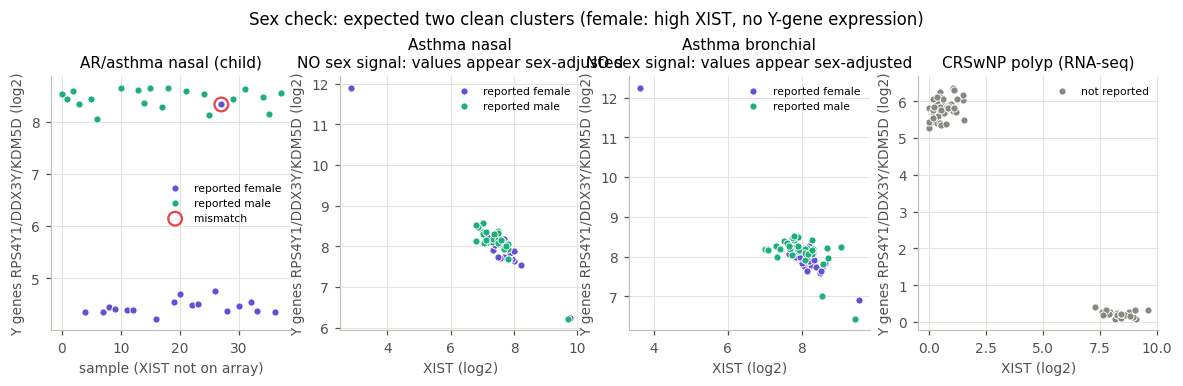

,dataset,samples with reported sex,Y-gene gap M−F (log2),inferred F,inferred M,mismatches,mismatched samples
0,AR/asthma nasal (child),38,3.79,17.0,21.0,1,GSM475645
1,Asthma nasal,56,0.06,NaN,NaN,not testable,–
2,Asthma bronchial,79,0.03,NaN,NaN,not testable,–
3,CRSwNP polyp (RNA-seq),0,NaN,22.0,48.0,0,–


In [7]:
def infer_sex(x):
    y = x.loc[[g for g in ["RPS4Y1", "DDX3Y", "KDM5D", "EIF1AY"] if g in x.index]].mean()
    score = y - x.loc["XIST"] if "XIST" in x.index else y
    srt = np.sort(score.values)
    cut = srt[np.argmax(np.diff(srt))] + np.max(np.diff(srt)) / 2
    return pd.Series(np.where(score > cut, "M", "F"), index=x.columns), y

sex_rows = []
fig, axes = plt.subplots(1, 4, figsize=(13, 3.0))
for ax, name in zip(axes, ["AR/asthma nasal (child)", "Asthma nasal", "Asthma bronchial",
                           "CRSwNP polyp (RNA-seq)"]):
    d = datasets[name]; x = d["expr"]
    pred, ys = infer_sex(x)
    xs = x.loc["XIST"] if "XIST" in x.index else pd.Series(np.arange(x.shape[1]), index=x.columns)
    sexcol = next((c for c in ["gender", "sex"] if c in d["meta"].columns), None)
    rep = d["meta"][sexcol].str[0].str.upper() if sexcol else pd.Series("?", index=x.columns)
    has_rep = rep.isin(["M", "F"])
    gap = ys[rep == "M"].mean() - ys[rep == "F"].mean() if has_rep.any() else np.nan
    sex_signal = not (has_rep.any() and gap < 1)
    mismatch = [s for s in x.columns if sex_signal and rep[s] in ("M", "F") and rep[s] != pred[s]]
    for sx, colr, lab in [("F", C_VIOLET, "reported female"), ("M", C_AQUA, "reported male"),
                          ("?", C_MUTED, "not reported")]:
        sel = (rep == sx).values
        if sel.any():
            ax.scatter(xs[sel], ys[sel], s=22, c=colr, label=lab, edgecolor="white", lw=0.6)
    if mismatch:
        ax.scatter(xs[mismatch], ys[mismatch], s=80, facecolor="none", edgecolor=C_DIS, lw=1.5,
                   label="mismatch")
    ax.set(title=name + ("" if sex_signal else "\nNO sex signal: values appear sex-adjusted"),
           xlabel="XIST (log2)" if "XIST" in x.index else "sample (XIST not on array)",
           ylabel="Y genes RPS4Y1/DDX3Y/KDM5D (log2)")
    ax.legend(fontsize=7, loc="best")
    sex_rows.append({"dataset": name, "samples with reported sex": int((rep != "?").sum()),
                     "Y-gene gap M−F (log2)": None if np.isnan(gap) else round(float(gap), 2),
                     "inferred F": int((pred == "F").sum()) if sex_signal else None,
                     "inferred M": int((pred == "M").sum()) if sex_signal else None,
                     "mismatches": len(mismatch) if sex_signal else "not testable",
                     "mismatched samples": ", ".join(mismatch) or "–"})
fig.suptitle("Sex check: expected two clean clusters (female: high XIST, no Y-gene expression)", y=1.08)
savefig(fig, "qc_sex_check")
sex_table = pd.DataFrame(sex_rows)
sex_table

### QC check: tissue identity markers

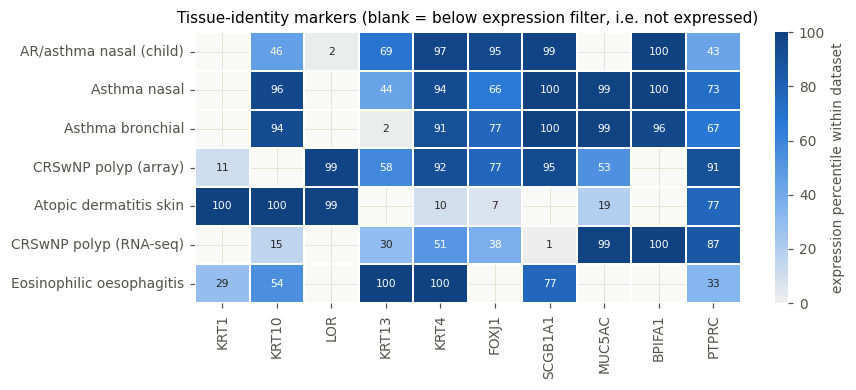

In [8]:
markers = ["KRT1", "KRT10", "LOR", "KRT13", "KRT4", "FOXJ1", "SCGB1A1", "MUC5AC", "BPIFA1", "PTPRC"]
tissue_mat = pd.DataFrame({name: d["expr"].median(axis=1).rank(pct=True).reindex(markers) * 100
                           for name, d in datasets.items()}).T
fig, ax = plt.subplots(figsize=(8, 3.2))
seq = matplotlib.colors.LinearSegmentedColormap.from_list("blueseq", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])
sns.heatmap(tissue_mat, cmap=seq, vmin=0, vmax=100, annot=tissue_mat.round(0).fillna(-1).astype(int).astype(str)
            .replace("-1", "filtered"), fmt="", annot_kws={"size": 7}, mask=tissue_mat.isna(),
            cbar_kws={"label": "expression percentile within dataset"}, ax=ax, linewidths=1, linecolor="white")
ax.set_facecolor("#f9f9f7")
ax.set(title="Tissue-identity markers (blank = below expression filter, i.e. not expressed)", xlabel="", ylabel="")
savefig(fig, "qc_tissue_markers")

**QC interpretation.**

* **Suspicious finding:** four of the five microarray matrices are on a log2 scale (max ≈ 14–16), but
  **GSE36830 is not** (median ≈ 1, max ≈ 328: linear, median-scaled MAS5-type values). Analysing it as
  if it were log2 would have produced meaningless fold changes, so it was log2-transformed (values
  floored at their 0.1th percentile). GSE41861 contains missing values for some probes; those genes
  were dropped. RNA-seq data were normalised as described. The expression filter removes unexpressed
  probes/genes (before/after counts in the QC table).
* No technical duplicate samples were found; the outlier rule flags any sample with an unusually low
  correlation to the rest of its study (listed in the table – removed).
* **Sex check (two findings).** (i) In GSE19187 and GSE136825 samples split into two clean clusters
  (high *XIST*/no Y-gene signal vs the reverse), as biology requires. One GSE19187 sample recorded as
  female clearly expresses Y-chromosome genes (listed in the table) – a probable metadata error. We keep
  it because sex is not our variable of interest, but it is a warning that GEO annotations are not
  infallible. (ii) **In GSE41861 (both tissues) there is no sex signal at all**: *XIST* and
  *RPS4Y1/DDX3Y/KDM5D* have the same mean in reported males and females (gap ≈ 0 log2 units, versus
  ≈ 4 in GSE19187). That is biologically impossible for raw data, so the deposited values were almost
  certainly adjusted for sex (and possibly other covariates) before submission. The consequence is that
  sex cannot be checked there, and we must verify that the *disease* signal survives – which the
  positive-control genes in Stage 5 do (*POSTN*, *CLCA1*, *SERPINB2* are up in asthmatic bronchi).
* **Tissue markers** behave as biology requires: epidermal keratins (*KRT1/KRT10*, *LOR*) are high only in
  skin; squamous oesophageal keratins (*KRT13/KRT4*) dominate the oesophagus; airway epithelial and
  ciliated-cell genes (*SCGB1A1*, *BPIFA1*, *FOXJ1*, *MUC5AC*) are high in nasal and bronchial brushings;
  polyp/turbinate tissue shows immune infiltrate (*PTPRC*). The data are what they claim to be.

## Stage 4 – Exploratory data analysis

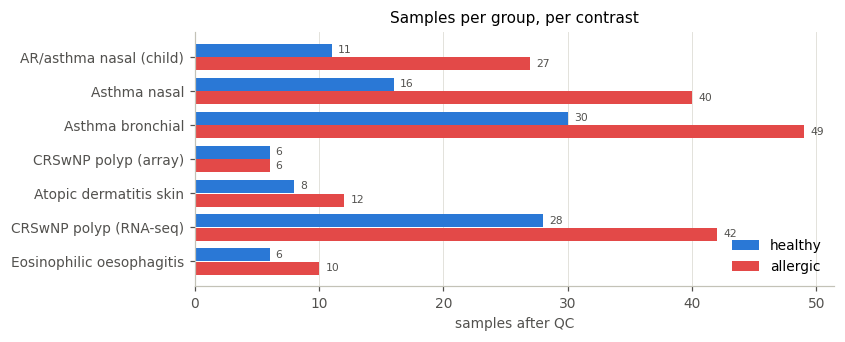

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3))
s = summary.set_index("dataset")[["healthy", "allergic"]].copy()
s["healthy"] = [int((datasets[k]["label"] == 0).sum()) for k in s.index]
s["allergic"] = [int(datasets[k]["label"].sum()) for k in s.index]
y = np.arange(len(s))
ax.barh(y - 0.2, s["healthy"], 0.38, color=C_CTRL, label="healthy")
ax.barh(y + 0.2, s["allergic"], 0.38, color=C_DIS, label="allergic")
for yi, (h, a) in enumerate(zip(s["healthy"], s["allergic"])):
    ax.text(h + 0.5, yi - 0.2, str(h), va="center", fontsize=7, color="#52514e")
    ax.text(a + 0.5, yi + 0.2, str(a), va="center", fontsize=7, color="#52514e")
ax.set_yticks(y, s.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(xlabel="samples after QC", title="Samples per group, per contrast"); ax.legend(loc="lower right")
savefig(fig, "eda_sample_counts")

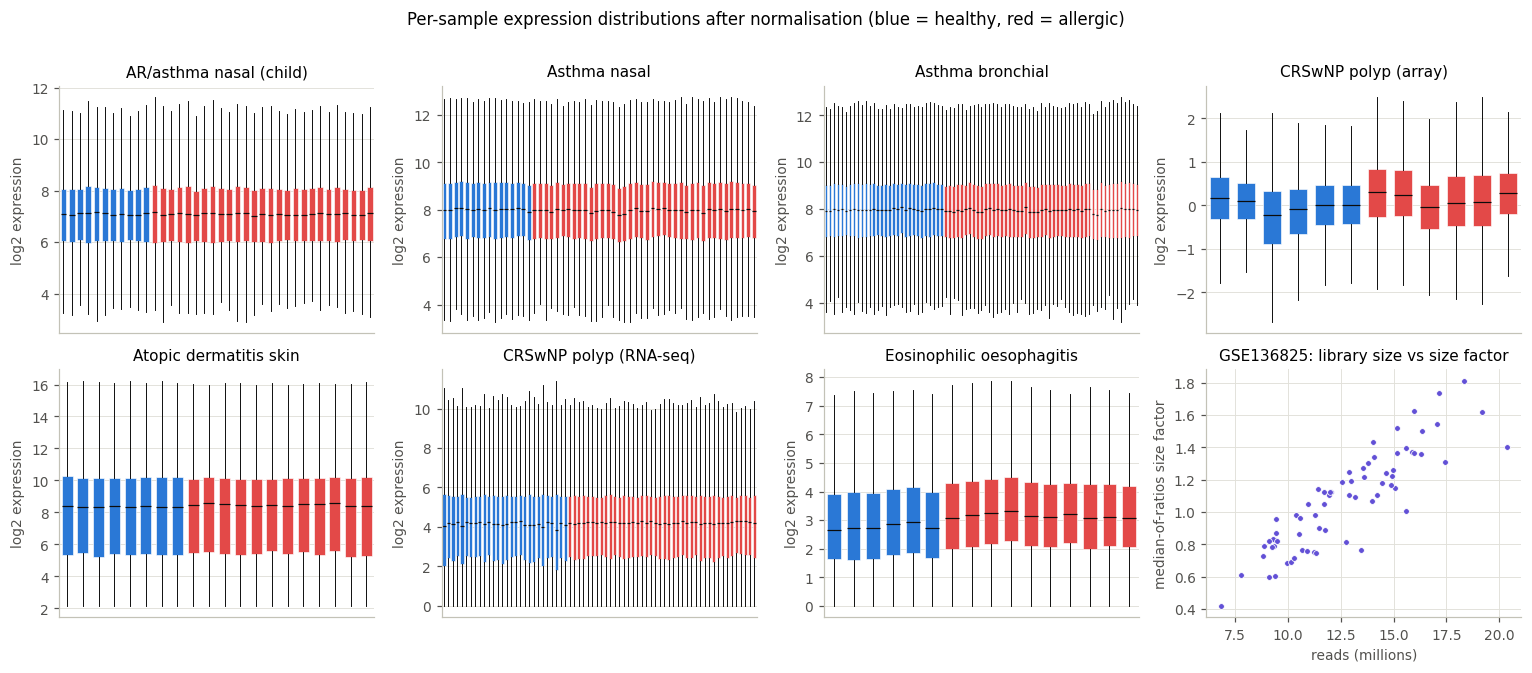

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, d) in zip(axes.flat, datasets.items()):
    x = d["expr"]; labl = d["label"].loc[x.columns]
    order = labl.sort_values().index
    bp = ax.boxplot(x[order].values, showfliers=False, patch_artist=True, widths=0.7,
                    medianprops=dict(color=C_INK, lw=0.8), whiskerprops=dict(lw=0.6), capprops=dict(lw=0))
    for patch, l in zip(bp["boxes"], labl.loc[order]):
        patch.set(facecolor=C_DIS if l else C_CTRL, edgecolor="white", lw=0.4)
    ax.set(title=name, xticks=[], ylabel="log2 expression"); ax.grid(axis="x", visible=False)
ax = axes.flat[-1]
if "libsize" in datasets["CRSwNP polyp (RNA-seq)"]:
    d = datasets["CRSwNP polyp (RNA-seq)"]
    ax.scatter(d["libsize"] / 1e6, d["size_factors"].reindex(d["libsize"].index), s=14, c=C_VIOLET, edgecolor="white", lw=0.5)
    ax.set(title="GSE136825: library size vs size factor", xlabel="reads (millions)", ylabel="median-of-ratios size factor")
fig.suptitle("Per-sample expression distributions after normalisation (blue = healthy, red = allergic)", y=1.01)
fig.tight_layout()
savefig(fig, "eda_distributions")

**Interpretation.** Within each study, per-sample distributions are well aligned after normalisation,
with no group-wise shift that would masquerade as differential expression. For the RNA-seq study,
size factors track library depth, as expected – depth differences are removed by normalisation.

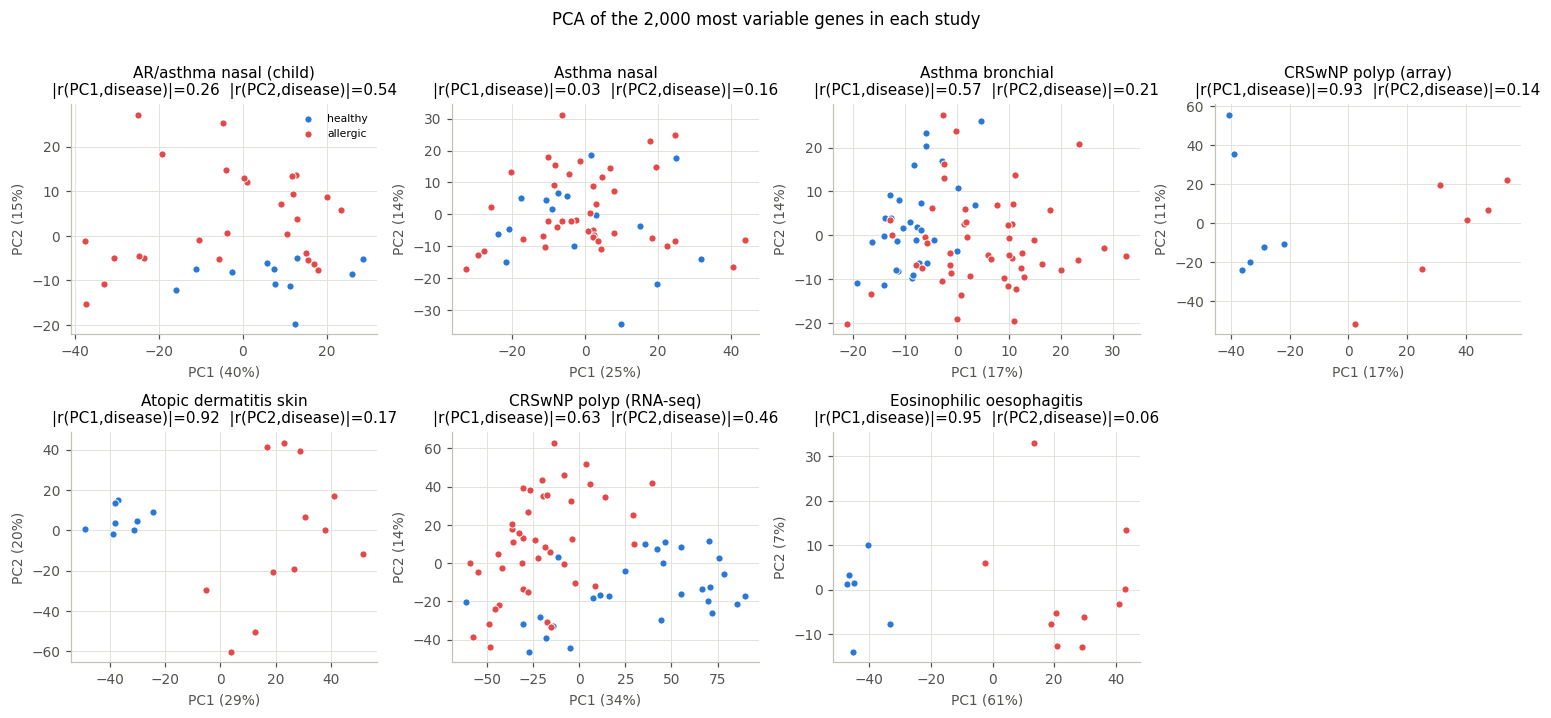

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
pca_store = {}
for ax, (name, d) in zip(axes.flat, datasets.items()):
    x = d["expr"]
    top = x.var(axis=1).sort_values(ascending=False).index[:2000]
    z = x.loc[top].sub(x.loc[top].mean(axis=1), axis=0).T
    pca = PCA(n_components=2, random_state=SEED).fit(z)
    pcs = pca.transform(z)
    labl = d["label"].loc[x.columns].values
    for v, colr, lab in [(0, C_CTRL, "healthy"), (1, C_DIS, "allergic")]:
        ax.scatter(pcs[labl == v, 0], pcs[labl == v, 1], s=22, c=colr, label=lab, edgecolor="white", lw=0.6)
    r = pca.explained_variance_ratio_
    rpc = [abs(stats.pointbiserialr(labl, pcs[:, i])[0]) for i in range(2)]
    ax.set(title=f"{name}\n|r(PC1,disease)|={rpc[0]:.2f}  |r(PC2,disease)|={rpc[1]:.2f}",
           xlabel=f"PC1 ({r[0]:.0%})", ylabel=f"PC2 ({r[1]:.0%})")
    pca_store[name] = dict(pc1=pcs[:, 0].round(2).tolist(), pc2=pcs[:, 1].round(2).tolist(),
                           label=labl.tolist(), var=[round(float(v), 3) for v in r],
                           samples=list(x.columns), r=[round(float(v), 2) for v in rpc])
axes.flat[0].legend(fontsize=7)
axes.flat[-1].axis("off")
fig.suptitle("PCA of the 2,000 most variable genes in each study", y=1.01)
fig.tight_layout()
savefig(fig, "eda_pca")
DASH["pca"] = pca_store

**Interpretation.** Disease status is the dominant source of variation in tissue-level studies with
strong inflammation (atopic dermatitis lesional skin, nasal polyps, EoE) – PC1 separates the groups
almost completely. In the epithelial-brushing studies (asthma, childhood rhinitis) disease explains
much less of the total variance (|r| with PC1/PC2 is low): inter-individual variation dominates and the
disease signal is subtler. This tells us to expect many more DEGs in the tissue studies and to weight
evidence across studies rather than by DEG counts.

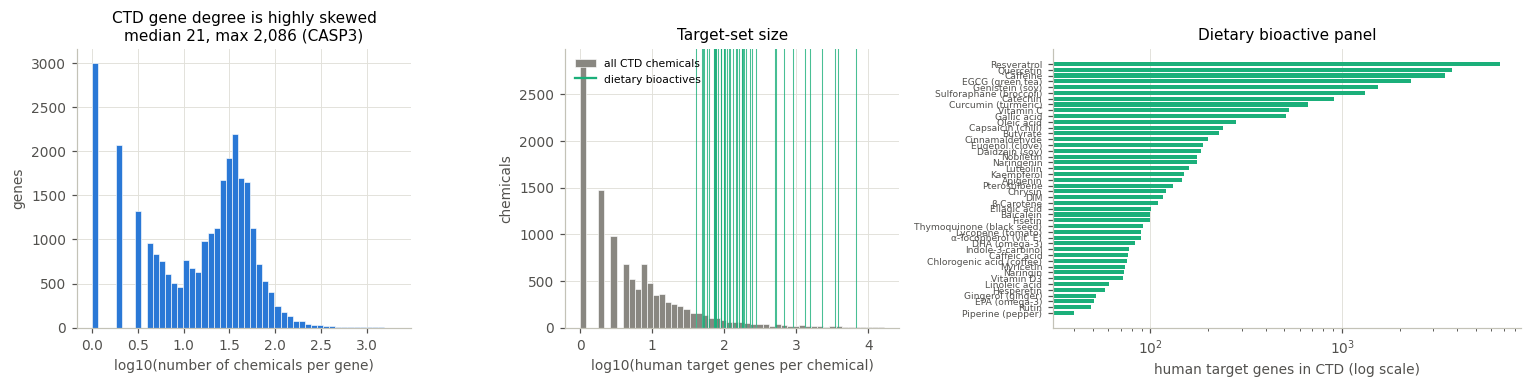

In [12]:
gene_degree = ctd.groupby("GeneSymbol").ChemicalName.nunique()
chem_size = ctd.groupby("ChemicalName").GeneSymbol.nunique()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.4]})
ax = axes[0]
ax.hist(np.log10(gene_degree), bins=50, color=C_CTRL, edgecolor="white", lw=0.4)
ax.set(xlabel="log10(number of chemicals per gene)", ylabel="genes",
       title=f"CTD gene degree is highly skewed\nmedian {gene_degree.median():.0f}, max {gene_degree.max():,} ({gene_degree.idxmax()})")
ax = axes[1]
ax.hist(np.log10(chem_size), bins=50, color=C_MUTED, edgecolor="white", lw=0.4, label="all CTD chemicals")
for c in BIOACTIVES:
    ax.axvline(np.log10(chem_size[c]), color=C_AQUA, lw=0.7, alpha=0.8)
ax.plot([], [], color=C_AQUA, label="dietary bioactives")
ax.set(xlabel="log10(human target genes per chemical)", ylabel="chemicals", title="Target-set size")
ax.legend(fontsize=7)
ax = axes[2]
bs = bio_targets.rename(index={k: v[0] for k, v in BIOACTIVES.items()}).sort_values()
ax.barh(bs.index, bs.values, color=C_AQUA, height=0.7)
ax.set_xscale("log"); ax.tick_params(axis="y", labelsize=6); ax.grid(axis="y", visible=False)
ax.set(xlabel="human target genes in CTD (log scale)", title="Dietary bioactive panel")
fig.tight_layout()
savefig(fig, "eda_ctd")

**Interpretation.** CTD knowledge is extremely uneven: a few genes (e.g. *CYP1A1*, *TNF*, *IL6*, *HMOX1*,
*CASP3*) have been studied with thousands of chemicals, while most genes have a handful. Inflammatory
genes are both the most studied *and* the ones we expect to change in allergy, so a naive
hypergeometric test would find "enrichment" for almost any chemical. **This is the key confounder the
core analysis must correct for** (degree-matched null). Bioactive target-set sizes span two orders of
magnitude (resveratrol and quercetin ≈ thousands; hesperetin ≈ 60), so we use size-aware statistics.

## Stage 5 – Core analysis

### 5a. Differential expression in each study (O1)

For each contrast we fit a two-group linear model per gene and use **empirical-Bayes moderated
t-statistics** (the limma method of Smyth 2004, implemented below in NumPy/SciPy so the notebook needs no R).
Moderation borrows information across genes to stabilise variance estimates, which matters for the small
studies. P-values are corrected with **Benjamini–Hochberg FDR** within each study. A gene is called a
DEG at FDR < 0.05 and |log2FC| ≥ 0.5 (≥ 1.41-fold). For RNA-seq this is the "limma-trend" approach on
log-CPM values.

In [13]:
def trigamma_inverse(x):
    y = 0.5 + 1.0 / x
    for _ in range(50):
        tri = special.polygamma(1, y)
        dif = tri * (1 - tri / x) / special.polygamma(2, y)
        y = y + dif
        if np.all(np.abs(-dif / y) < 1e-8):
            break
    return y

def moderated_t(x, label):
    lab = np.asarray(label).astype(bool)
    a, b = x.values[:, lab], x.values[:, ~lab]
    n1, n0 = a.shape[1], b.shape[1]
    lfc = a.mean(1) - b.mean(1)
    dg = n1 + n0 - 2
    s2 = ((a.var(1, ddof=1) * (n1 - 1)) + (b.var(1, ddof=1) * (n0 - 1))) / dg
    s2 = np.maximum(s2, 1e-8)
    z = np.log(s2)
    e = z - special.digamma(dg / 2) + np.log(dg / 2)
    emean, evar = e.mean(), e.var(ddof=1) - special.polygamma(1, dg / 2)
    if evar > 0:
        d0 = 2 * trigamma_inverse(evar)
        s02 = np.exp(emean + special.digamma(d0 / 2) - np.log(d0 / 2))
    else:
        d0, s02 = np.inf, np.exp(emean)
    s2post = s2 if np.isinf(d0) else (d0 * s02 + dg * s2) / (d0 + dg)
    df = dg + (0 if np.isinf(d0) else d0)
    t = lfc / np.sqrt(s2post * (1 / n1 + 1 / n0))
    p = 2 * stats.t.sf(np.abs(t), df if np.isfinite(df) else 1e6)
    res = pd.DataFrame({"log2FC": lfc, "t": t, "p": p, "mean_expr": x.values.mean(1)}, index=x.index)
    res["FDR"] = multipletests(res.p, method="fdr_bh")[1]
    return res, dict(d0=float(d0), s02=float(s02), n1=n1, n0=n0)

FDR_T, LFC_T = 0.05, 0.5
de = {}
de_rows = []
for name, d in datasets.items():
    x = d["expr"]; lab = d["label"].loc[x.columns]
    r, prior = moderated_t(x, lab)
    r["DEG"] = np.where((r.FDR < FDR_T) & (r.log2FC >= LFC_T), "up",
                np.where((r.FDR < FDR_T) & (r.log2FC <= -LFC_T), "down", "ns"))
    de[name] = r
    r.to_csv(RES / f"DE_{re.sub('[^A-Za-z0-9]+', '_', name)}.csv")
    de_rows.append({"dataset": name, "genes tested": len(r), "n allergic": prior["n1"], "n healthy": prior["n0"],
                    "prior df d0": round(prior["d0"], 1), "up": int((r.DEG == "up").sum()),
                    "down": int((r.DEG == "down").sum()), "min FDR": f"{r.FDR.min():.1e}"})
de_summary = pd.DataFrame(de_rows)
de_summary

,dataset,genes tested,n allergic,n healthy,prior df d0,up,down,min FDR
0,AR/asthma nasal (child),15228,27,11,3.9,41,2,2.7e-09
1,Asthma nasal,11834,40,16,3.1,42,24,1.3e-06
2,Asthma bronchial,11732,49,30,3.5,59,124,1.1e-06
3,CRSwNP polyp (array),16678,6,6,2.0,554,200,2.0e-04
4,Atopic dermatitis skin,15837,12,8,0.9,1975,1408,4.1e-09
5,CRSwNP polyp (RNA-seq),16687,42,28,3.4,2343,1523,1.0e-13
6,Eosinophilic oesophagitis,12282,10,6,3.4,4359,875,2.1e-11


#### Positive controls – does the analysis recover known allergy biology?
Type-2 (IL-13-induced) epithelial genes are the best-established markers: *POSTN*, *CLCA1* and *SERPINB2*
(Woodruff et al. 2007), *CST1*, *CCL26* (eotaxin-3, the top EoE gene), *ALOX15*, *CPA3* (mast cells), *CLC*
(eosinophils). If they did not go up, something would be wrong with our labels or processing.

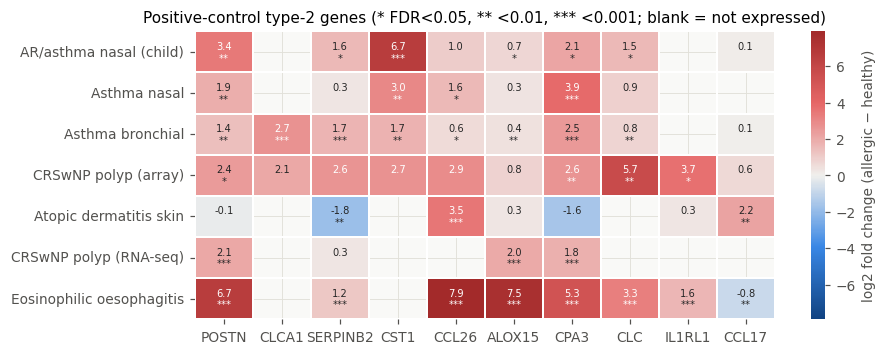

significant positive-control results: 34 up, 2 down (of 53 measured)


In [14]:
POS_CTRL = ["POSTN", "CLCA1", "SERPINB2", "CST1", "CCL26", "ALOX15", "CPA3", "CLC", "IL1RL1", "CCL17"]
pc = pd.DataFrame({n: r.reindex(POS_CTRL)["log2FC"] for n, r in de.items()}).T
pcf = pd.DataFrame({n: r.reindex(POS_CTRL)["FDR"] for n, r in de.items()}).T
fig, ax = plt.subplots(figsize=(8.5, 3.4))
stars = pcf.map(lambda v: "" if pd.isna(v) else ("***" if v < 0.001 else "**" if v < 0.01 else "*" if v < 0.05 else ""))
annot_txt = pc.round(1).astype(str).where(pc.notna(), "") + "\n" + stars.where(pc.notna(), "")
lim = np.nanmax(np.abs(pc.values))
sns.heatmap(pc, cmap=DIVERGING, center=0, vmin=-lim, vmax=lim, annot=annot_txt, fmt="", annot_kws={"size": 6.5},
            mask=pc.isna(), linewidths=1, linecolor="white", cbar_kws={"label": "log2 fold change (allergic − healthy)"}, ax=ax)
ax.set_facecolor("#f9f9f7")
ax.set(title="Positive-control type-2 genes (* FDR<0.05, ** <0.01, *** <0.001; blank = not expressed)", xlabel="", ylabel="")
savefig(fig, "de_positive_controls")
pos_up = int(((pc > 0) & (pcf < 0.05)).sum().sum()); pos_down = int(((pc < 0) & (pcf < 0.05)).sum().sum())
print(f"significant positive-control results: {pos_up} up, {pos_down} down (of {int(pc.notna().sum().sum())} measured)")
DASH["positive_controls"] = {"genes": POS_CTRL, "datasets": list(pc.index),
                             "lfc": pc.round(2).where(pc.notna(), None).values.tolist(),
                             "fdr": pcf.where(pcf.notna(), None).map(lambda v: None if v is None else float(f"{v:.2e}")).values.tolist()}

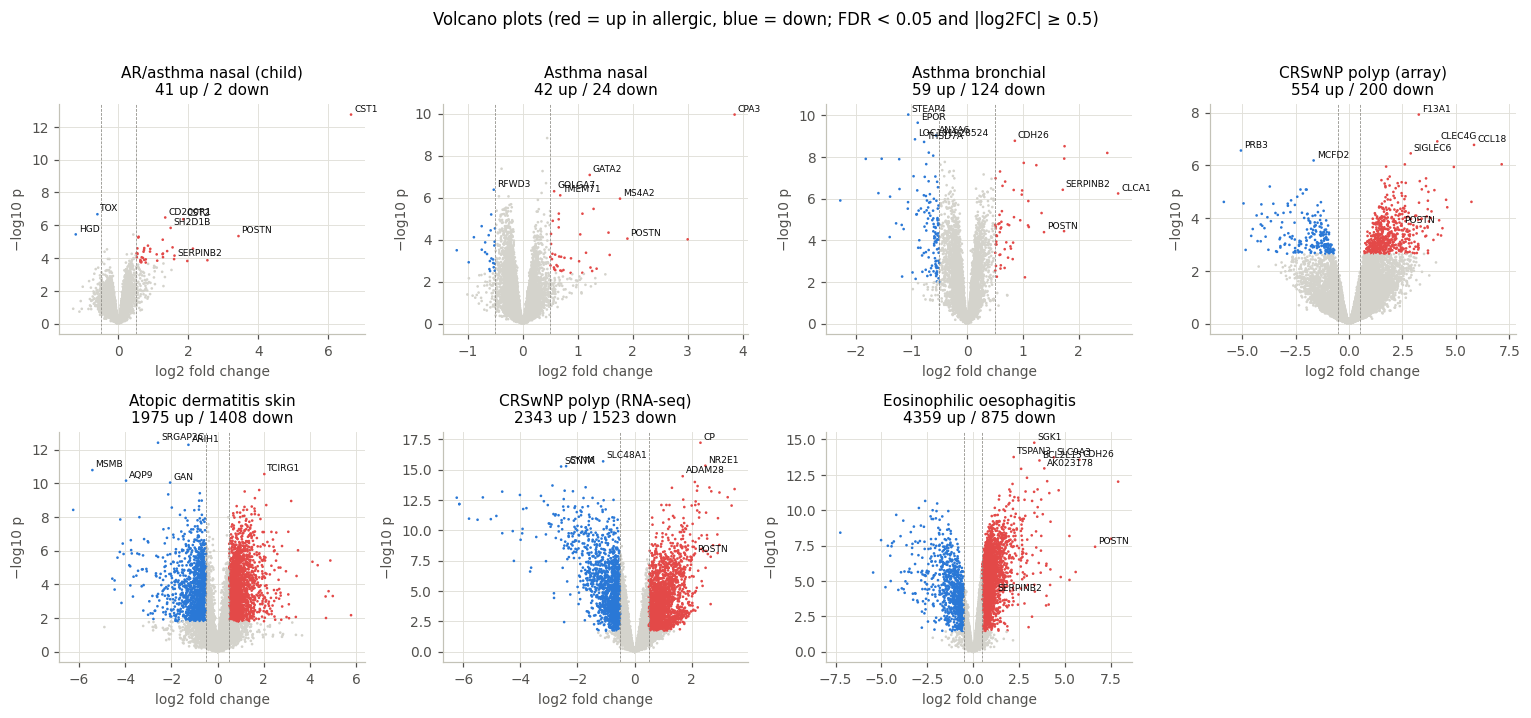

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
for ax, (name, r) in zip(axes.flat, de.items()):
    nl = -np.log10(r.p.clip(lower=1e-300))
    col = r.DEG.map({"up": C_DIS, "down": C_CTRL, "ns": "#d4d3cc"})
    ax.scatter(r.log2FC, nl, s=3, c=col, linewidths=0, rasterized=True)
    lab_genes = r[r.DEG != "ns"].sort_values("p").head(6).index.union([g for g in POS_CTRL[:3] if g in r.index and r.loc[g, "DEG"] == "up"])
    for g in lab_genes:
        ax.annotate(g, (r.loc[g, "log2FC"], nl[g]), fontsize=6, color=C_INK, xytext=(2, 2), textcoords="offset points")
    ax.axvline(LFC_T, color=C_MUTED, lw=0.5, ls="--"); ax.axvline(-LFC_T, color=C_MUTED, lw=0.5, ls="--")
    ax.set(title=f"{name}\n{(r.DEG=='up').sum()} up / {(r.DEG=='down').sum()} down", xlabel="log2 fold change", ylabel="−log10 p")
axes.flat[-1].axis("off")
fig.suptitle("Volcano plots (red = up in allergic, blue = down; FDR < 0.05 and |log2FC| ≥ 0.5)", y=1.01)
fig.tight_layout()
savefig(fig, "de_volcanoes")

vol = {}
for name, r in de.items():
    sig = r[r.DEG != "ns"]; ns_ = r[r.DEG == "ns"]
    ns_ = ns_.sample(min(1500, len(ns_)), random_state=SEED)
    sub = pd.concat([sig.sort_values("p").head(1500), ns_])
    vol[name] = {"g": sub.index.tolist(), "x": sub.log2FC.round(3).tolist(),
                 "y": (-np.log10(sub.p.clip(lower=1e-300))).round(3).tolist(), "c": sub.DEG.tolist()}
DASH["volcano"] = vol
DASH["de_summary"] = de_summary.to_dict(orient="records")

**Interpretation.** The expected type-2 biology is recovered: 34 of 53 measured positive-control results are
significantly *up* and only 2 are down. *POSTN*, *CST1*, *SERPINB2*, *CLCA1*, *CPA3* and *CCL26* rise in airway, sinus
and oesophageal disease; in atopic-dermatitis skin the airway IL-13 epithelial genes do not move (they are airway
genes) but the skin type-2 chemokines *CCL26* and *CCL17* (TARC, a clinical AD biomarker) do. This validates the labels,
the probe mapping and the GSE36830 log-transformation, and shows the disease signal survived whatever adjustment
was applied to GSE41861. The number of DEGs differs by two
orders of magnitude between studies, mirroring the PCA: inflamed tissue (AD skin, polyps, EoE) gives
thousands of DEGs, while epithelial brushings in asthma give tens to hundreds. A DEG count alone is
therefore a poor basis for comparing studies, which motivates the meta-analysis below.

### 5b. Consensus cross-tissue allergy signature (O1)

For every gene measured in ≥ 5 of the 7 contrasts we combine evidence with a **weighted Stouffer
meta-analysis**: each study's moderated-t p-value is converted to a signed z-score and weighted by
√(sample size). Combined p-values are BH-corrected. The **consensus signature** is every gene with
(i) meta-analysis FDR < 0.01, (ii) the same direction of change in ≥ 75 % of the studies measuring it, and
(iii) individually significant (FDR < 0.05) in ≥ 2 studies – so no single strong study can create a
signature gene on its own.

In [16]:
DSN = list(datasets)

def consensus(names, min_studies=5, fdr=0.01, consist=0.75, min_sig=2):
    zs = pd.DataFrame({n: np.sign(de[n].t) * stats.norm.isf(de[n].p.clip(lower=1e-300) / 2) for n in names})
    lfc = pd.DataFrame({n: de[n].log2FC for n in names})
    sig = pd.DataFrame({n: (de[n].FDR < 0.05) for n in names})
    w = pd.Series({n: np.sqrt(len(datasets[n]["label"])) for n in names})
    keep = zs.notna().sum(axis=1) >= min(min_studies, len(names) - 1)
    zs, lfc, sig = zs[keep], lfc[keep], sig[keep].fillna(False)
    W = zs.notna() * w
    Z = (zs.fillna(0) * w).sum(axis=1) / np.sqrt((W ** 2).sum(axis=1))
    out = pd.DataFrame({"Z": Z, "p": 2 * stats.norm.sf(np.abs(Z)), "n_studies": zs.notna().sum(axis=1),
                        "mean_log2FC": lfc.mean(axis=1)})
    out["FDR"] = multipletests(out.p, method="fdr_bh")[1]
    out["dir"] = np.sign(out.Z).astype(int)
    agree = (np.sign(lfc).eq(out.dir, axis=0) & lfc.notna()).sum(axis=1)
    out["frac_same_dir"] = agree / out.n_studies
    out["n_sig_same_dir"] = (sig & np.sign(lfc).eq(out.dir, axis=0)).sum(axis=1)
    out["signature"] = (out.FDR < fdr) & (out.frac_same_dir >= consist) & (out.n_sig_same_dir >= min_sig)
    return out.sort_values("p"), lfc

meta, lfc_mat = consensus(DSN)
SIG = meta[meta.signature]
SIG_UP, SIG_DOWN = set(SIG.index[SIG.dir > 0]), set(SIG.index[SIG.dir < 0])
print(f"genes in meta-analysis universe: {len(meta):,}")
print(f"consensus signature: {len(SIG)} genes ({len(SIG_UP)} up, {len(SIG_DOWN)} down in allergy)")
meta.to_csv(RES / "consensus_meta_analysis.csv")
SIG.head(25)[["Z", "FDR", "mean_log2FC", "n_studies", "frac_same_dir", "n_sig_same_dir"]]

genes in meta-analysis universe: 11,870
consensus signature: 1177 genes (860 up, 317 down in allergy)


/tmp/ipykernel_128544/3132202112.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  zs, lfc, sig = zs[keep], lfc[keep], sig[keep].fillna(False)


,Z,FDR,mean_log2FC,n_studies,frac_same_dir,n_sig_same_dir
CPA3,11.897444,1.436983e-28,2.377205,7,0.857143,6
CDH26,11.840115,1.436983e-28,1.804607,7,1.000000,5
SAMSN1,10.435323,6.767139e-22,1.500175,7,1.000000,6
POSTN,10.161370,8.751276e-21,2.536562,7,0.857143,6
SERPINB4,9.570868,2.516713e-18,3.205137,5,1.000000,4
MS4A2,9.307658,2.585324e-17,1.294661,6,0.833333,5
CTSC,9.197525,6.211210e-17,1.222027,7,1.000000,6
BCL2L15,9.165398,7.324474e-17,1.072292,7,1.000000,4
CCL26,8.985544,3.395574e-16,2.911307,6,1.000000,4
SFXN1,8.806461,1.533117e-15,0.500707,7,1.000000,4


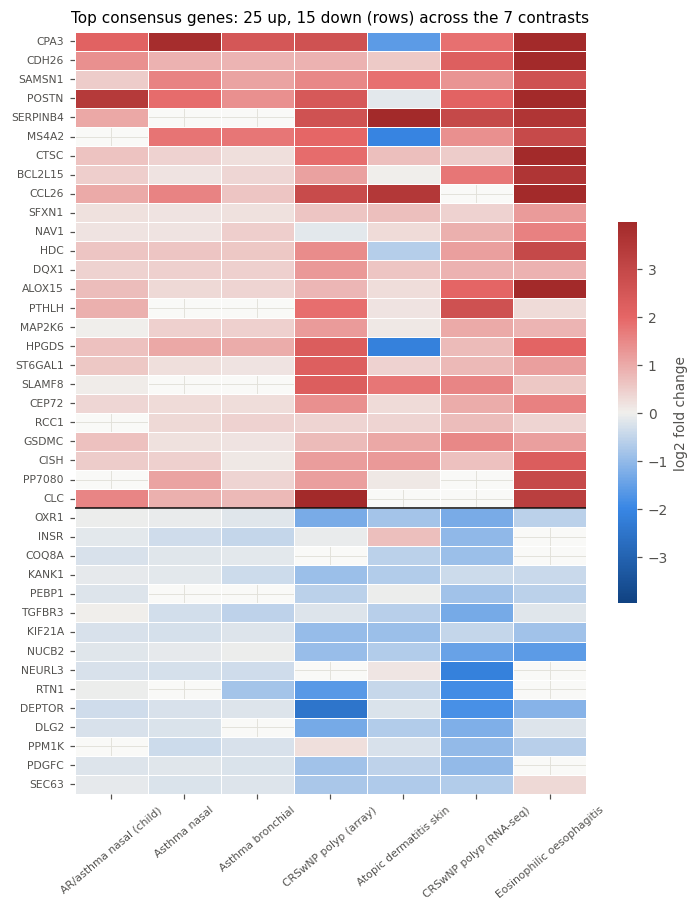

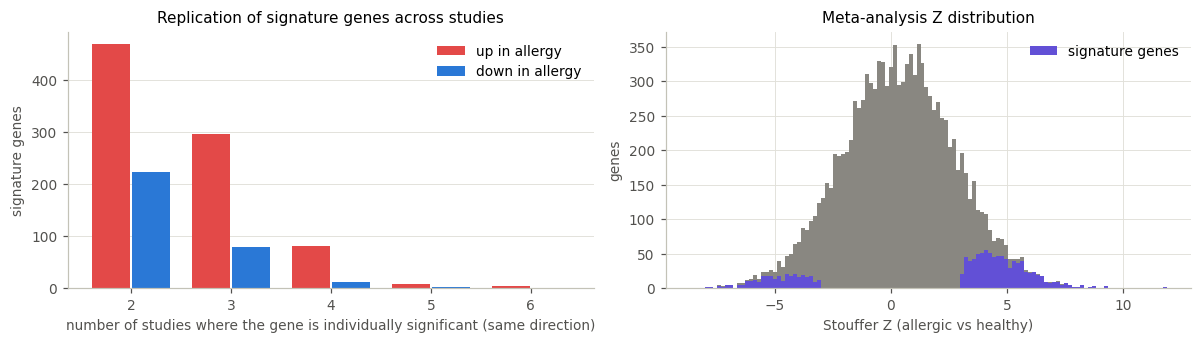

In [17]:
top = pd.concat([SIG[SIG.dir > 0].head(25), SIG[SIG.dir < 0].head(15)]).index
hm = lfc_mat.loc[top, DSN]
fig, ax = plt.subplots(figsize=(7.5, 9))
lim = np.nanpercentile(np.abs(hm.values), 97)
sns.heatmap(hm, cmap=DIVERGING, center=0, vmin=-lim, vmax=lim, mask=hm.isna(), linewidths=0.6, linecolor="white",
            cbar_kws={"label": "log2 fold change", "shrink": 0.5}, ax=ax)
ax.set_facecolor("#f9f9f7")
ax.axhline(25, color=C_INK, lw=1)
ax.set(title="Top consensus genes: 25 up, 15 down (rows) across the 7 contrasts", xlabel="", ylabel="")
ax.tick_params(axis="y", labelsize=7); ax.tick_params(axis="x", rotation=40, labelsize=7)
savefig(fig, "consensus_heatmap")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ax = axes[0]
cnt_up = SIG[SIG.dir > 0].n_sig_same_dir.value_counts().sort_index()
cnt_dn = SIG[SIG.dir < 0].n_sig_same_dir.value_counts().sort_index()
idx = sorted(set(cnt_up.index) | set(cnt_dn.index))
xx = np.arange(len(idx))
ax.bar(xx - 0.2, cnt_up.reindex(idx, fill_value=0), 0.38, color=C_DIS, label="up in allergy")
ax.bar(xx + 0.2, cnt_dn.reindex(idx, fill_value=0), 0.38, color=C_CTRL, label="down in allergy")
ax.set_xticks(xx, idx); ax.grid(axis="x", visible=False)
ax.set(xlabel="number of studies where the gene is individually significant (same direction)",
       ylabel="signature genes", title="Replication of signature genes across studies"); ax.legend()
ax = axes[1]
ax.hist(meta.Z, bins=120, color=C_MUTED, edgecolor="none")
ax.hist(SIG.Z, bins=120, color=C_VIOLET, edgecolor="none", label="signature genes")
ax.set(xlabel="Stouffer Z (allergic vs healthy)", ylabel="genes", title="Meta-analysis Z distribution"); ax.legend()
fig.tight_layout()
savefig(fig, "consensus_replication")

DASH["consensus"] = {
    "n_universe": int(len(meta)), "n_sig": int(len(SIG)), "n_up": len(SIG_UP), "n_down": len(SIG_DOWN),
    "heatmap": {"genes": list(top), "datasets": DSN, "lfc": hm.round(2).where(hm.notna(), None).values.tolist()},
    "table": SIG.reset_index(names="gene").head(300)[["gene", "Z", "FDR", "mean_log2FC", "n_studies", "frac_same_dir",
                                                      "n_sig_same_dir"]].round(4).to_dict(orient="records"),
}

**Interpretation.** The consensus signature is dominated by up-regulated genes, and the top of the list is a
who's-who of type-2 and allergic inflammation (e.g. *POSTN*, *SERPINB2*, *CST1*, *CCL26*, *ALOX15*, mast-cell and
eosinophil genes), shared by organs as different as nose, skin and oesophagus: *CPA3*, *MS4A2* (FcεRIβ), *HDC* and
*HPGDS* are mast-cell genes; *CDH26*, *POSTN*, *ALOX15*, *CCL26* and *SERPINB4* are IL-13-induced epithelial genes.
Down-regulated genes are fewer and smaller in effect (metabolic and nuclear-receptor genes, see 6a). Most signature genes replicate in only 2–3
individual studies – expected given the very different tissues – but none rests on a single study by
construction. This signature is the reference set for testing the dietary bioactives.

### 5c. Are dietary-bioactive targets enriched in the allergy signature? (O2, H1–H2)

**The trap.** In CTD, the most-studied genes (cytokines, stress-response and apoptosis genes) are linked to
thousands of chemicals, and the same genes are often inflammatory DEGs. A naive hypergeometric test would make
almost *any* chemical look "anti-allergic". We therefore use two baselines:

1. **Degree-matched null (H1).** Genes in the universe are split into 10 bins by CTD degree (number of
   chemicals curated against the gene). A compound's null overlap with the signature is the sum, over bins,
   of the overlap expected when drawing the same number of target genes *from the same bin*. That sum of
   independent hypergeometric variables has an exact mean and variance (→ z-score) and is simulated 20,000 times
   for an empirical p-value. Fold enrichment = observed / degree-matched expected overlap.
2. **All other CTD chemicals (H2).** The same degree-adjusted fold enrichment is computed for every CTD
   chemical with ≥ 20 targets in the universe. If dietary bioactives are special, they should beat the typical
   non-dietary chemical (one-sided Mann–Whitney; plus a regression adjusting for target-set size).

Universe = genes in the meta-analysis that have at least one human CTD interaction.

In [18]:
U = sorted(set(meta.index) & set(gene_degree.index))
Uidx = {g: i for i, g in enumerate(U)}
in_sig = np.isin(U, list(SIG.index))
deg_U = gene_degree.reindex(U).values
bins = pd.qcut(pd.Series(deg_U).rank(method="first"), 10, labels=False).values
N_b = np.bincount(bins, minlength=10)
K_b = np.bincount(bins, weights=in_sig, minlength=10).astype(int)
print(f"universe: {len(U):,} genes, of which {in_sig.sum()} signature genes ({in_sig.mean():.1%})")
deg_by_bin = pd.DataFrame({"degree range": [f"{deg_U[bins==b].min()}–{deg_U[bins==b].max()}" for b in range(10)],
                           "genes": N_b, "signature genes": K_b, "signature %": (100 * K_b / N_b).round(1)})
print("Signature genes are concentrated in highly-studied genes:")
print(deg_by_bin.to_string())

chem_targets_U = (ctd[ctd.GeneSymbol.isin(Uidx)].groupby("ChemicalName").GeneSymbol
                  .agg(lambda s: np.unique([Uidx[g] for g in s])))
chem_targets_U = chem_targets_U[chem_targets_U.map(len) >= 20]
print(f"chemicals with ≥20 targets in the universe: {len(chem_targets_U):,} "
      f"({sum(c in chem_targets_U.index for c in BIOACTIVES)} of {len(BIOACTIVES)} bioactives)")

def enrichment_stats(idx, n_sim=0):
    k_b = np.bincount(bins[idx], minlength=10)
    obs = int(in_sig[idx].sum())
    p_b = K_b / N_b
    mean = float((k_b * p_b).sum())
    var = float((k_b * p_b * (1 - p_b) * (N_b - k_b) / np.maximum(N_b - 1, 1)).sum())
    M, n, N = len(U), int(in_sig.sum()), len(idx)
    naive_exp = N * n / M
    out = dict(n_targets=len(idx), overlap=obs, expected_naive=naive_exp, FE_naive=obs / naive_exp if naive_exp else np.nan,
               p_naive=stats.hypergeom.sf(obs - 1, M, n, N), expected_degmatched=mean,
               FE_degmatched=obs / mean if mean > 0 else np.nan, z_degmatched=(obs - mean) / np.sqrt(var) if var > 0 else np.nan)
    if n_sim:
        sims = sum(rng.hypergeometric(K_b[b], N_b[b] - K_b[b], k_b[b], size=n_sim) for b in range(10) if k_b[b] > 0)
        out["p_degmatched"] = (1 + (sims >= obs).sum()) / (n_sim + 1)
    return out

all_chem = pd.DataFrame({c: enrichment_stats(idx) for c, idx in chem_targets_U.items()}).T
all_chem["dietary"] = all_chem.index.isin(list(BIOACTIVES))
all_chem = all_chem.astype({"n_targets": int, "overlap": int, "dietary": bool})

bio = pd.DataFrame({c: enrichment_stats(chem_targets_U[c], n_sim=20000) for c in BIOACTIVES}).T
bio["FDR_naive"] = multipletests(bio.p_naive.astype(float), method="fdr_bh")[1]
bio["FDR_degmatched"] = multipletests(bio.p_degmatched.astype(float), method="fdr_bh")[1]
bio.insert(0, "compound", [BIOACTIVES[c][0] for c in bio.index])
bio.insert(1, "class", [BIOACTIVES[c][1] for c in bio.index])
bio = bio.sort_values("FE_degmatched", ascending=False)
bio.to_csv(RES / "bioactive_enrichment.csv")
print(f"\nbioactives enriched at FDR<0.05 — naive test: {(bio.FDR_naive < 0.05).sum()}/{len(bio)};"
      f" degree-matched test: {(bio.FDR_degmatched < 0.05).sum()}/{len(bio)}")
bio[["compound", "class", "n_targets", "overlap", "expected_naive", "FE_naive", "FDR_naive",
     "expected_degmatched", "FE_degmatched", "z_degmatched", "FDR_degmatched"]].round(3)

universe: 11,385 genes, of which 1145 signature genes (10.1%)
Signature genes are concentrated in highly-studied genes:
  degree range  genes  signature genes  signature %
0         1–20   1139               96          8.4
1        20–26   1138               92          8.1
2        26–30   1139               82          7.2
3        30–34   1138              121         10.6
4        34–39   1139               98          8.6
5        39–44   1138              113          9.9
6        44–50   1138              105          9.2
7        50–59   1139              134         11.8
8        59–81   1138              128         11.2
9      81–2086   1139              176         15.5


chemicals with ≥20 targets in the universe: 1,558 (44 of 44 bioactives)



bioactives enriched at FDR<0.05 — naive test: 8/44; degree-matched test: 1/44


,compound,class,n_targets,overlap,expected_naive,FE_naive,FDR_naive,expected_degmatched,FE_degmatched,z_degmatched,FDR_degmatched
daidzein,Daidzein (soy),isoflavone,123.0,22.0,12.370,1.778,0.029,16.361,1.345,1.536,0.775
Chlorogenic Acid,Chlorogenic acid (coffee),phenolic acid,44.0,8.0,4.425,1.808,0.191,6.203,1.290,0.789,0.996
Eugenol,Eugenol (clove),spice compound,136.0,25.0,13.678,1.828,0.018,19.505,1.282,1.405,0.775
sulforaphane,Sulforaphane (broccoli),isothiocyanate,894.0,139.0,89.910,1.546,0.000,109.622,1.268,3.335,0.029
Ascorbic Acid,Vitamin C,vitamin,329.0,56.0,33.088,1.692,0.001,45.032,1.244,1.904,0.543
fisetin,Fisetin,flavonoid,72.0,13.0,7.241,1.795,0.127,10.930,1.189,0.700,0.996
Linoleic Acid,Linoleic acid,fatty acid,34.0,6.0,3.419,1.755,0.295,5.047,1.189,0.466,0.996
baicalein,Baicalein,flavonoid,68.0,12.0,6.839,1.755,0.164,10.237,1.172,0.615,0.996
Capsaicin,Capsaicin (chili),spice compound,177.0,30.0,17.801,1.685,0.019,25.667,1.169,0.981,0.996
indole-3-carbinol,Indole-3-carbinol,indole,62.0,11.0,6.235,1.764,0.164,9.501,1.158,0.542,0.996


In [19]:
cmp_ = all_chem.copy()
cmp_["log2FE"] = np.log2(cmp_.FE_degmatched.astype(float).clip(lower=1 / 16))
cmp_["log_size"] = np.log10(cmp_.n_targets)
lo, hi = cmp_.loc[cmp_.dietary, "n_targets"].min(), cmp_.loc[cmp_.dietary, "n_targets"].max()
size_matched = cmp_[(cmp_.n_targets >= lo) & (cmp_.n_targets <= hi)]
diet_fe = size_matched.loc[size_matched.dietary, "log2FE"]
other_fe = size_matched.loc[~size_matched.dietary, "log2FE"]
mw = stats.mannwhitneyu(diet_fe, other_fe, alternative="greater")
import statsmodels.formula.api as smf
ols = smf.ols("log2FE ~ dietary + log_size", data=size_matched.assign(dietary=size_matched.dietary.astype(int))).fit()
pct_rank = {c: float((other_fe < cmp_.loc[c, "log2FE"]).mean() * 100) for c in BIOACTIVES}
print(f"size-matched comparison: {len(diet_fe)} dietary vs {len(other_fe)} other chemicals")
print(f"median degree-adjusted log2FE: dietary {diet_fe.median():.2f} vs other {other_fe.median():.2f}; "
      f"Mann–Whitney one-sided p = {mw.pvalue:.3g}")
print(f"OLS log2FE ~ dietary + log10(size): dietary coef = {ols.params['dietary']:.3f} "
      f"(95% CI {ols.conf_int().loc['dietary', 0]:.3f} to {ols.conf_int().loc['dietary', 1]:.3f}), p = {ols.pvalues['dietary']:.3g}")
frac_naive_all = (cmp_.p_naive.astype(float) < 0.05).mean()
print(f"share of ALL CTD chemicals 'enriched' by the naive test at p<0.05: {frac_naive_all:.0%}")

size-matched comparison: 44 dietary vs 1046 other chemicals
median degree-adjusted log2FE: dietary -0.12 vs other -0.07; Mann–Whitney one-sided p = 0.752
OLS log2FE ~ dietary + log10(size): dietary coef = -0.028 (95% CI -0.184 to 0.128), p = 0.724
share of ALL CTD chemicals 'enriched' by the naive test at p<0.05: 20%


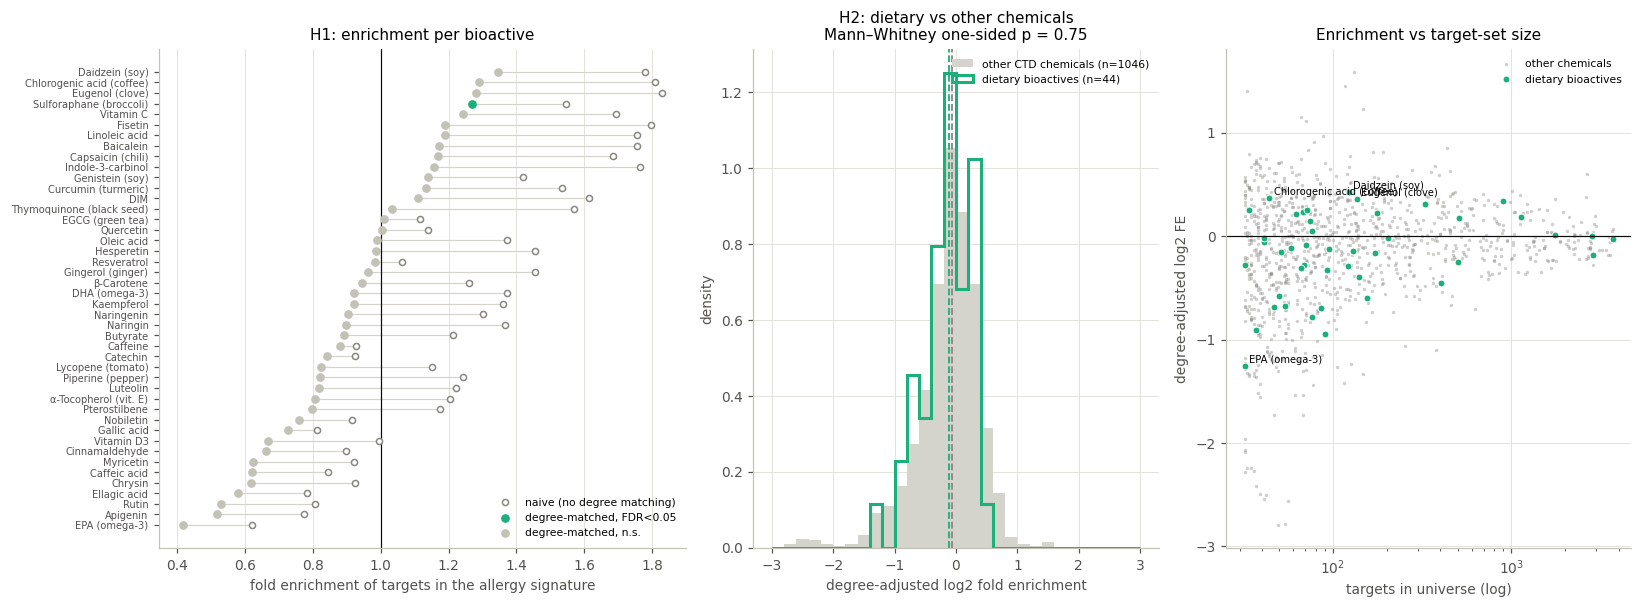

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
b = bio.sort_values("FE_degmatched")
yy = np.arange(len(b))
ax.scatter(b.FE_naive, yy, s=16, facecolor="white", edgecolor=C_MUTED, lw=1, label="naive (no degree matching)", zorder=3)
sigm = b.FDR_degmatched < 0.05
ax.scatter(b.FE_degmatched[sigm], yy[sigm], s=22, c=C_AQUA, label="degree-matched, FDR<0.05", zorder=4)
ax.scatter(b.FE_degmatched[~sigm], yy[~sigm], s=22, c="#c3c2b7", label="degree-matched, n.s.", zorder=4)
for yi, (a1, a2) in enumerate(zip(b.FE_naive, b.FE_degmatched)):
    ax.plot([a1, a2], [yi, yi], color="#d4d3cc", lw=0.8, zorder=2)
ax.axvline(1, color=C_INK, lw=0.8)
ax.set_yticks(yy, b.compound, fontsize=6.5); ax.grid(axis="y", visible=False)
ax.set(xlabel="fold enrichment of targets in the allergy signature", title="H1: enrichment per bioactive")
ax.legend(fontsize=7, loc="lower right")
ax = axes[1]
binsh = np.linspace(-3, 3, 31)
ax.hist(other_fe, bins=binsh, color="#d4d3cc", density=True, label=f"other CTD chemicals (n={len(other_fe)})")
ax.hist(diet_fe, bins=binsh, color=C_AQUA, histtype="step", lw=2, density=True, label=f"dietary bioactives (n={len(diet_fe)})")
ax.axvline(other_fe.median(), color=C_MUTED, lw=1.2, ls="--"); ax.axvline(diet_fe.median(), color=C_AQUA, lw=1.2, ls="--")
ax.set(xlabel="degree-adjusted log2 fold enrichment", ylabel="density",
       title=f"H2: dietary vs other chemicals\nMann–Whitney one-sided p = {mw.pvalue:.2g}")
ax.legend(fontsize=7)
ax = axes[2]
oth = size_matched[~size_matched.dietary]
ax.scatter(oth.n_targets, oth.log2FE, s=5, c=C_MUTED, alpha=0.4, linewidths=0, label="other chemicals", rasterized=True)
dd = size_matched[size_matched.dietary]
ax.scatter(dd.n_targets, dd.log2FE, s=20, c=C_AQUA, edgecolor="white", lw=0.6, label="dietary bioactives")
for c in dd.sort_values("log2FE").index[[0, -1, -2, -3]]:
    ax.annotate(BIOACTIVES[c][0], (dd.loc[c, "n_targets"], dd.loc[c, "log2FE"]), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
ax.set_xscale("log"); ax.axhline(0, color=C_INK, lw=0.8)
ax.set(xlabel="targets in universe (log)", ylabel="degree-adjusted log2 FE", title="Enrichment vs target-set size")
ax.legend(fontsize=7)
fig.tight_layout()
savefig(fig, "enrichment_bioactives")

hist_o, edges = np.histogram(other_fe, bins=binsh, density=True)
hist_d, _ = np.histogram(diet_fe, bins=binsh, density=True)
DASH["enrichment"] = {
    "table": bio.reset_index(names="ctd_name")[["ctd_name", "compound", "class", "n_targets", "overlap", "expected_naive", "FE_naive",
            "FDR_naive", "expected_degmatched", "FE_degmatched", "z_degmatched", "p_degmatched", "FDR_degmatched"]]
            .assign(pct_rank_vs_other=lambda t: t.ctd_name.map(pct_rank)).round(4).to_dict(orient="records"),
    "hist": {"edges": edges.round(3).tolist(), "other": hist_o.round(4).tolist(), "dietary": hist_d.round(4).tolist()},
    "mw_p": float(mw.pvalue), "median_diet": float(diet_fe.median()), "median_other": float(other_fe.median()),
    "n_other": int(len(other_fe)), "ols_coef": float(ols.params["dietary"]), "ols_p": float(ols.pvalues["dietary"]),
    "ols_ci": [float(v) for v in ols.conf_int().loc["dietary"]], "frac_naive_all": float(frac_naive_all),
    "deg_bins": deg_by_bin.to_dict(orient="records"), "n_universe": len(U), "n_sig_in_universe": int(in_sig.sum()),
    "scatter_other": oth.sample(min(1500, len(oth)), random_state=SEED)[["n_targets", "log2FE"]].round(3).values.tolist(),
    "scatter_diet": [[int(dd.loc[c, "n_targets"]), round(float(dd.loc[c, "log2FE"]), 3), BIOACTIVES[c][0]] for c in dd.index],
}

### 5d. Do bioactives push their targets *against* the disease direction? (O2, H3)

CTD records the direction of many interactions ("X results in **decreased** expression of *IL6* mRNA"). We keep
only simple, direct expression effects (`increases^expression` or `decreases^expression`, not effects on reactions),
give each compound–gene pair a net direction (+1/−1; ties dropped), and compare it with the gene's direction
in allergy (sign of the meta-analysis Z).

*Reversal fraction* = share of a compound's directional signature targets that it moves in the opposite
direction to disease. A naive null is 50 %, but that ignores two biases (most signature genes are *up* in allergy;
many compounds are mainly reported to *decrease* expression). So the **expected** reversal for each compound is
computed from its own up/down profile across the whole universe and the signature's up/down split, and the
observed reversal is tested against that expectation (binomial test). The same is done for every CTD chemical.

In [21]:
simple = ctd[ctd.InteractionActions.isin(["increases^expression", "decreases^expression"])].copy()
simple["d"] = np.where(simple.InteractionActions == "increases^expression", 1, -1)
direc = simple.groupby(["ChemicalName", "GeneSymbol"]).d.sum()
direc = np.sign(direc[direc != 0]).astype(int).rename("d").reset_index()
direc = direc[direc.GeneSymbol.isin(Uidx)]
dis_dir = meta.dir

def reversal(chem_df):
    g = chem_df.set_index("GeneSymbol").d
    on_sig = g[g.index.isin(SIG.index)]
    n = len(on_sig)
    if n == 0:
        return None
    s = dis_dir.loc[on_sig.index]
    rev = int((on_sig.values == -s.values).sum())
    p_dec = (g == -1).mean()
    p_up_sig = len(SIG_UP) / len(SIG)
    exp = p_dec * p_up_sig + (1 - p_dec) * (1 - p_up_sig)
    return dict(n_dir_sig=n, n_reversed=rev, reversal=rev / n, expected_reversal=exp, frac_decrease_overall=p_dec,
                p=stats.binomtest(rev, n, exp, alternative="greater").pvalue if n else np.nan,
                score=float(-(on_sig.values * s.values).mean()))

rev_all = pd.DataFrame({c: r for c, grp in direc.groupby("ChemicalName") if (r := reversal(grp)) is not None}).T
rev_all = rev_all[rev_all.n_dir_sig >= 10].astype(float)
rev_all["dietary"] = rev_all.index.isin(list(BIOACTIVES))
rev_all["excess"] = rev_all.reversal - rev_all.expected_reversal
rev_bio = rev_all[rev_all.dietary].copy()
rev_bio["FDR"] = multipletests(rev_bio.p, method="fdr_bh")[1]
rev_bio.insert(0, "compound", [BIOACTIVES[c][0] for c in rev_bio.index])
rev_bio = rev_bio.sort_values("excess", ascending=False)
rev_bio.to_csv(RES / "bioactive_reversal.csv")

pooled_rev, pooled_n = rev_bio.n_reversed.sum(), rev_bio.n_dir_sig.sum()
pooled_exp = (rev_bio.expected_reversal * rev_bio.n_dir_sig).sum() / pooled_n
mw_rev = stats.mannwhitneyu(rev_bio.excess, rev_all.loc[~rev_all.dietary, "excess"], alternative="greater")
print(f"{len(rev_bio)} bioactives and {int((~rev_all.dietary).sum())} other chemicals have ≥10 directional signature targets")
print(f"pooled bioactive reversal: {pooled_rev:.0f}/{pooled_n:.0f} = {pooled_rev / pooled_n:.1%} "
      f"(expected from direction biases {pooled_exp:.1%}; naive 50%)")
print(f"bioactives with significant excess reversal (FDR<0.05): {(rev_bio.FDR < 0.05).sum()}/{len(rev_bio)}")
print(f"excess reversal, dietary vs other chemicals: median {rev_bio.excess.median():+.3f} vs "
      f"{rev_all.loc[~rev_all.dietary, 'excess'].median():+.3f}; one-sided Mann–Whitney p = {mw_rev.pvalue:.3g}")
rev_bio[["compound", "n_dir_sig", "n_reversed", "reversal", "expected_reversal", "excess", "p", "FDR"]].round(3)

14 bioactives and 423 other chemicals have ≥10 directional signature targets
pooled bioactive reversal: 418/888 = 47.1% (expected from direction biases 50.4%; naive 50%)
bioactives with significant excess reversal (FDR<0.05): 0/14
excess reversal, dietary vs other chemicals: median -0.040 vs +0.003; one-sided Mann–Whitney p = 0.787


,compound,n_dir_sig,n_reversed,reversal,expected_reversal,excess,p,FDR
Curcumin,Curcumin (turmeric),49.0,34.0,0.694,0.548,0.146,0.027,0.372
epigallocatechin gallate,EGCG (green tea),46.0,28.0,0.609,0.491,0.118,0.073,0.513
Butyric Acid,Butyrate,17.0,9.0,0.529,0.420,0.110,0.249,0.873
Eugenol,Eugenol (clove),25.0,13.0,0.520,0.419,0.101,0.206,0.873
Gallic Acid,Gallic acid,27.0,15.0,0.556,0.551,0.005,0.559,0.993
Resveratrol,Resveratrol,107.0,49.0,0.458,0.474,-0.016,0.667,0.993
Caffeine,Caffeine,19.0,10.0,0.526,0.557,-0.031,0.693,0.993
Catechin,Catechin,11.0,5.0,0.455,0.504,-0.049,0.734,0.993
Genistein,Genistein (soy),121.0,51.0,0.421,0.481,-0.059,0.919,0.993
sulforaphane,Sulforaphane (broccoli),134.0,61.0,0.455,0.521,-0.065,0.946,0.993


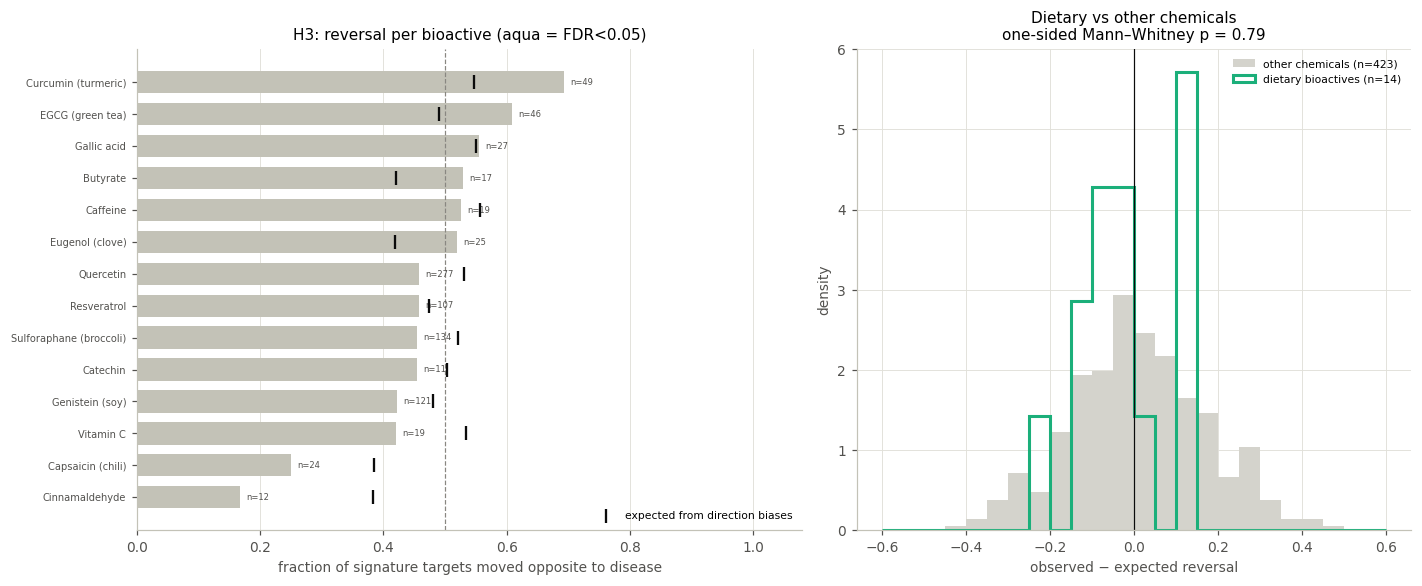

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
rb = rev_bio.sort_values("reversal")
yy = np.arange(len(rb))
ax.barh(yy, rb.reversal, color=np.where(rb.FDR < 0.05, C_AQUA, "#c3c2b7"), height=0.7)
ax.scatter(rb.expected_reversal, yy, marker="|", s=90, c=C_INK, lw=1.5, label="expected from direction biases", zorder=4)
ax.axvline(0.5, color=C_MUTED, lw=0.8, ls="--")
for yi, (r_, n_) in enumerate(zip(rb.reversal, rb.n_dir_sig)):
    ax.text(r_ + 0.01, yi, f"n={int(n_)}", va="center", fontsize=5.5, color="#52514e")
ax.set_yticks(yy, rb.compound, fontsize=6.5); ax.grid(axis="y", visible=False); ax.set_xlim(0, 1.08)
ax.set(xlabel="fraction of signature targets moved opposite to disease", title="H3: reversal per bioactive (aqua = FDR<0.05)")
ax.legend(fontsize=7, loc="lower right")
ax = axes[1]
oth_ex = rev_all.loc[~rev_all.dietary, "excess"]
binsr = np.linspace(-0.6, 0.6, 25)
ax.hist(oth_ex, bins=binsr, density=True, color="#d4d3cc", label=f"other chemicals (n={len(oth_ex)})")
ax.hist(rev_bio.excess, bins=binsr, density=True, color=C_AQUA, histtype="step", lw=2, label=f"dietary bioactives (n={len(rev_bio)})")
ax.axvline(0, color=C_INK, lw=0.8)
ax.set(xlabel="observed − expected reversal", ylabel="density", title=f"Dietary vs other chemicals\none-sided Mann–Whitney p = {mw_rev.pvalue:.2g}")
ax.legend(fontsize=7)
fig.tight_layout()
savefig(fig, "reversal_bioactives")

hr_o, er = np.histogram(oth_ex, bins=binsr, density=True)
hr_d, _ = np.histogram(rev_bio.excess, bins=binsr, density=True)
DASH["reversal"] = {
    "table": rev_bio.reset_index(names="ctd_name")[["ctd_name", "compound", "n_dir_sig", "n_reversed", "reversal",
             "expected_reversal", "excess", "p", "FDR"]].round(4).to_dict(orient="records"),
    "pooled": [int(pooled_rev), int(pooled_n), float(pooled_exp)], "mw_p": float(mw_rev.pvalue),
    "median_diet": float(rev_bio.excess.median()), "median_other": float(oth_ex.median()), "n_other": int(len(oth_ex)),
    "hist": {"edges": er.round(3).tolist(), "other": hr_o.round(4).tolist(), "dietary": hr_d.round(4).tolist()},
}

**Interpretation of 5c–5d (the core answer).**

* **The naive analysis is misleading.** Without degree matching, 8 of 44 bioactives (e.g. sulforaphane, genistein,
  curcumin, vitamin C, eugenol, quercetin) appear significantly "enriched" in the allergy signature – and so do
  ~20 % of *all* CTD chemicals. The degree table shows why: signature genes make up 15.5 % of the most-studied
  decile of genes but only ~8 % of the least-studied, so any chemical whose targets are well-studied genes
  inherits an apparent enrichment.
* **H1 – largely not supported.** After degree matching, only **sulforaphane** (the broccoli isothiocyanate and
  NRF2 activator) remains significantly enriched (≈ 1.27-fold, FDR ≈ 0.03). The other 43 compounds sit around a
  fold-enrichment of 1, several below it.
* **H2 – not supported.** Dietary bioactives are no more enriched than size-matched non-dietary CTD chemicals
  (medians ≈ −0.1 vs −0.07 log2; one-sided Mann–Whitney p ≈ 0.75; regression coefficient ≈ 0, CI spanning
  −0.18 to +0.13). Being "dietary" carries no special connection to allergy genes in curated data.
* **H3 – not supported.** Pooled over the 14 bioactives with enough directional data, 47 % of signature-gene
  effects oppose disease – slightly *below* the 50 % expected from direction biases. No compound reaches FDR <
  0.05; curcumin (69 % vs 55 % expected, nominal p ≈ 0.03) and EGCG are the best candidates and the most
  plausible leads for follow-up, but not significant after correction. Quercetin – the flavonoid most often
  promoted as "anti-allergic" – moves signature genes in the disease direction slightly more often than expected.

## Stage 6 – Biological interpretation (O3)

### 6a. Reactome pathway enrichment
Over-representation analysis (hypergeometric test, BH-FDR) of up- and down-regulated signature genes against the
meta-analysis universe, using Reactome human pathways with 10–500 genes in the universe. We also test the
signature genes that sulforaphane targets – the one compound that passed H1 – to see what biology the overlap is made of.

Reactome pathways: 2874 total, 1487 with 10–500 genes in the universe


Up in allergy: 860 genes, 22 pathways at FDR<0.05
Down in allergy: 317 genes, 5 pathways at FDR<0.05
Sulforaphane-targeted signature genes: 139 genes, 48 pathways at FDR<0.05


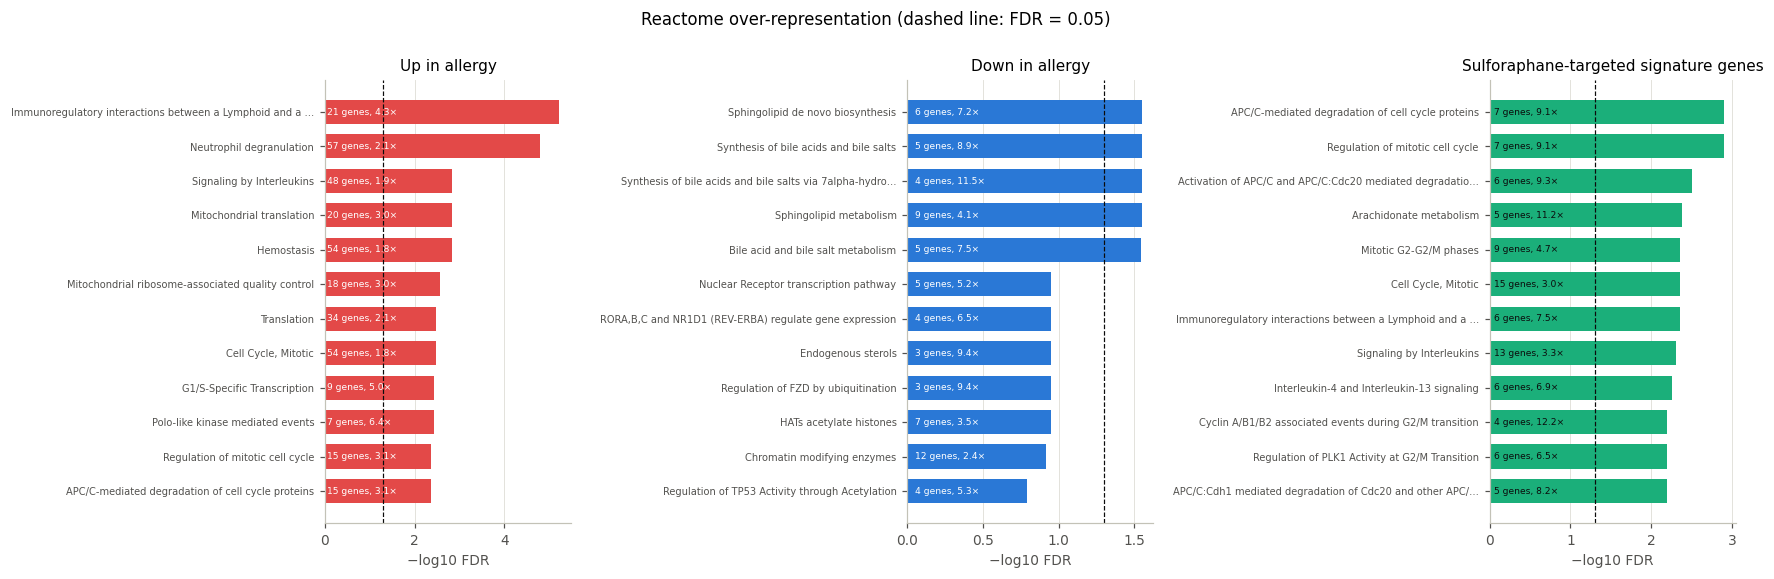

,pathway,size,overlap,FE,FDR,genes
0,Immunoregulatory interactions between a Lympho...,68,21,4.262483,0.000006,"CD1C, CD200R1, CD22, CD247, CD300A, CD33, CD3D..."
1,Neutrophil degranulation,369,57,2.132067,0.000016,"ADAM10, ALDOA, ARHGAP45, ARL8A, ARPC5, BIN2, B..."
2,Signaling by Interleukins,340,48,1.948564,0.001454,"AIP, ALOX15, BATF, CBL, CCR1, CCR5, CD86, CISH..."
3,Mitochondrial translation,92,20,3.000506,0.001454,"CHCHD1, GADD45GIP1, MALSU1, MRPL12, MRPL17, MR..."
4,Hemostasis,404,54,1.844865,0.001454,"ALDOA, APBB1IP, ARRB2, CD109, CD44, CD48, CD58..."
5,Mitochondrial ribosome-associated quality control,82,18,3.029779,0.002720,"CHCHD1, GADD45GIP1, MALSU1, MRPL12, MRPL17, MR..."
6,Translation,223,34,2.104390,0.003401,"CHCHD1, DARS2, EEF1E1, EIF3H, FARS2, GADD45GIP..."
7,"Cell Cycle, Mitotic",423,54,1.761999,0.003401,"AURKA, AURKB, BORA, BUB1, BUB1B, CCNA2, CCNB1,..."
8,G1/S-Specific Transcription,25,9,4.968837,0.003613,"CDC25A, CDC45, E2F1, E2F4, FBXO5, RBL1, RRM2, ..."
9,Polo-like kinase mediated events,15,7,6.441085,0.003613,"CCNB1, CCNB2, CDC25A, FOXM1, MYBL2, PKMYT1, PLK1"


In [23]:
with zipfile.ZipFile(RAW / "reactome" / "ReactomePathways.gmt.zip") as zf:
    gmt_lines = zf.read(zf.namelist()[0]).decode().splitlines()
reactome = {}
for line in gmt_lines:
    name, pid, *genes = line.split("\t")
    reactome[(pid, name)] = set(genes)
universe_set = set(meta.index)
reactome_u = {k: v & universe_set for k, v in reactome.items()}
reactome_u = {k: v for k, v in reactome_u.items() if 10 <= len(v) <= 500}
print(f"Reactome pathways: {len(reactome)} total, {len(reactome_u)} with 10–500 genes in the universe")

def ora(genes, universe=universe_set, sets=reactome_u):
    genes = set(genes) & universe
    M, n = len(universe), len(genes)
    rows = []
    for (pid, name), s in sets.items():
        k = len(genes & s)
        if k < 2:
            continue
        rows.append({"pathway": name, "id": pid, "size": len(s), "overlap": k, "expected": len(s) * n / M,
                     "FE": k / (len(s) * n / M), "p": stats.hypergeom.sf(k - 1, M, len(s), n),
                     "genes": ", ".join(sorted(genes & s)[:12])})
    out = pd.DataFrame(rows)
    out["FDR"] = multipletests(out.p, method="fdr_bh")[1]
    return out.sort_values("p").reset_index(drop=True)

sulf_targets = {U[i] for i in chem_targets_U["sulforaphane"]}
ora_sets = {"Up in allergy": SIG_UP, "Down in allergy": SIG_DOWN,
            "Sulforaphane-targeted signature genes": sulf_targets & set(SIG.index)}
ora_res = {k: ora(v) for k, v in ora_sets.items()}
for k, v in ora_res.items():
    v.to_csv(RES / f"reactome_{re.sub('[^A-Za-z]+', '_', k)}.csv", index=False)
    print(f"{k}: {len(ora_sets[k] & universe_set)} genes, {int((v.FDR < 0.05).sum())} pathways at FDR<0.05")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, (k, v), colr in zip(axes, ora_res.items(), [C_DIS, C_CTRL, C_AQUA]):
    t = v.head(12).iloc[::-1]
    ax.barh([p[:55] + ("…" if len(p) > 55 else "") for p in t.pathway], -np.log10(t.FDR), color=colr, height=0.7)
    ax.axvline(-np.log10(0.05), color=C_INK, lw=0.8, ls="--")
    for yi, (fe, ov) in enumerate(zip(t.FE, t.overlap)):
        ax.text(0.05, yi, f"{ov} genes, {fe:.1f}×", va="center", fontsize=6, color="white" if colr != C_AQUA else C_INK)
    ax.tick_params(axis="y", labelsize=6.5); ax.grid(axis="y", visible=False)
    ax.set(xlabel="−log10 FDR", title=k)
fig.suptitle("Reactome over-representation (dashed line: FDR = 0.05)", y=1.0)
fig.tight_layout()
savefig(fig, "reactome_enrichment")
DASH["reactome"] = {k: v.head(20).round(6).to_dict(orient="records") for k, v in ora_res.items()}
ora_res["Up in allergy"].head(10)[["pathway", "size", "overlap", "FE", "FDR", "genes"]]

### 6b. External validation with CTD curated gene–disease evidence
Does our data-driven signature recover genes that experts have curated (from the literature) as markers or
mechanisms of allergic disease – and *not* genes of unrelated diseases? We test both the naive and the
degree-matched enrichment, because curated disease genes are also well-studied genes.

In [24]:
cgd = pd.read_csv(RAW / "ctd" / "CTD_curated_genes_diseases.tsv.gz", sep="\t", comment="#", header=None,
                  names=["GeneSymbol", "GeneID", "DiseaseName", "DiseaseID", "DirectEvidence", "OmimIDs", "PubMedIDs"], dtype=str)
DISEASE_SETS = {
    "Allergic diseases (asthma, AD, AR, hypersensitivity, EoE, polyps, sinusitis)":
        ["MESH:D001249", "MESH:D003876", "MESH:D065631", "MESH:D006967", "MESH:D006969", "MESH:D057765",
         "MESH:D009298", "MESH:D012852", "MESH:D005512"],
    "Asthma": ["MESH:D001249"], "Atopic dermatitis": ["MESH:D003876"],
    "Negative control: Alzheimer disease": ["MESH:D000544"], "Negative control: Parkinson disease": ["MESH:D010300"],
    "Negative control: Schizophrenia": ["MESH:D012559"], "Negative control: Type 2 diabetes": ["MESH:D003924"],
}
val_rows = []
for k, ids in DISEASE_SETS.items():
    genes = set(cgd.loc[cgd.DiseaseID.isin(ids), "GeneSymbol"]) & set(U)
    idx = np.array([Uidx[g] for g in genes])
    r = enrichment_stats(idx, n_sim=20000)
    val_rows.append({"gene set": k, "curated genes in universe": len(genes), "in signature": r["overlap"],
                     "FE naive": r["FE_naive"], "p naive": r["p_naive"], "FE degree-matched": r["FE_degmatched"],
                     "p degree-matched": r["p_degmatched"],
                     "example genes": ", ".join(sorted(genes & set(SIG.index))[:10])})
validation = pd.DataFrame(val_rows)
DASH["validation"] = validation.round(5).to_dict(orient="records")
validation.round(4)

,gene set,curated genes in universe,in signature,FE naive,p naive,FE degree-matched,p degree-matched,example genes
0,"Allergic diseases (asthma, AD, AR, hypersensit...",116,14,1.2000,0.2755,0.9168,0.6858,"ALOX15, CCR1, CCR5, CD274, HNMT, HRH1, IL4R, K..."
1,Asthma,57,6,1.0467,0.5172,0.7572,0.8264,"HNMT, IL4R, MMP9, PLAU, SPRY2, TNC"
2,Atopic dermatitis,22,1,0.4520,0.9031,0.3642,0.9480,CCR5
3,Negative control: Alzheimer disease,70,10,1.4205,0.1620,1.1331,0.3853,"ABI3, ADAM10, BAX, CD33, DHCR24, ENO1, INSR, P..."
4,Negative control: Parkinson disease,47,6,1.2693,0.3333,0.9632,0.6036,"DNM1L, GSTA4, INSR, MAP2, PINK1, RAB32"
5,Negative control: Schizophrenia,86,12,1.3874,0.1522,1.1820,0.3121,"AHI1, APOL2, CCDC137, DPYD, FAM3D, GPR153, GSK..."
6,Negative control: Type 2 diabetes,103,11,1.0619,0.4642,0.8446,0.7743,"BAX, CMIP, CPT1A, GPX1, IRS2, JADE2, SLC2A1, S..."


**Interpretation.**
* **Up-regulated genes** map to immune pathways – immunoregulatory lymphoid/non-lymphoid interactions
  (Siglecs, CD1C, CD200R1), *signalling by interleukins* (incl. IL-4/IL-13 targets such as *ALOX15*, *CISH*,
  *CCR1/5*, *CSF2RA*), neutrophil degranulation and haemostasis (infiltrating granulocytes, mast cells, platelets) –
  plus a strong **mitotic cell-cycle / proliferation** module (*AURKA/B*, *PLK1*, *CCNB1/2*, *FOXM1*) and
  mitochondrial translation. This is the textbook picture of type-2 tissue inflammation with epithelial
  hyperplasia and immune-cell expansion.
* **Down-regulated genes** are enriched for **de novo sphingolipid (ceramide) synthesis** (*DEGS1/2*, *SPTLC3*,
  *SPTSSB*), bile-acid/sterol metabolism and nuclear-receptor signalling (*RXRA*, *RORC*, *NR3C2*). Reduced ceramides
  are a hallmark of the defective skin barrier in atopic dermatitis, and the strongest asthma GWAS locus
  (*ORMDL3*) is a regulator of the same sphingolipid pathway – a biologically meaningful link to barrier dysfunction.
* The **sulforaphane overlap** is made mostly of *mitotic cell-cycle* genes (*AURKA*, *PLK1*, *CCNB1*, *CDC20*) plus
  arachidonate metabolism (*ALOX5AP*, *HPGDS*, *PTGS1*, *GPX1/4*) and IL-4/IL-13 signalling. The cell-cycle part
  reflects that sulforaphane was largely studied as an anti-cancer agent in tumour cell lines; only the eicosanoid /
  redox part is specific to allergic biology. So even the one positive enrichment is partly an artefact of *why* the
  compound was studied, not evidence of an anti-allergic mechanism.
* **External validation – a negative result.** Genes curated in CTD for allergic diseases are **not** enriched in
  our signature (14 of 116; fold-enrichment ≈ 1.2 naive, ≈ 0.9 degree-matched; p > 0.25), and neither are the
  negative-control diseases. Inspecting the curated list explains why: it consists of genetic-association loci
  (*GSDMB*, *IKZF3*, HLA genes, *CDHR3*), xenobiotic genes from toxicology papers (*CYP1A1*, *GSTM1*) and T-cell cytokines
  (*IL4*, *IL5*, *IL13*) that are made by rare cells and are below detection in bulk tissue. Susceptibility genes and
  genes whose *expression* changes in tissue are different things. Our signature is validated by the type-2
  positive controls (5a) and pathway biology instead, but this result shows the limits of curated-gene validation.

### 6c. Compound–gene network (NetworkX)
Bipartite network: the 44 bioactives and the signature genes they target in CTD. Edges are coloured by whether the
compound's reported effect *opposes* (reversal) or *matches* the disease direction. We ask which signature genes are
network hubs (targeted by many compounds), whether those hubs are reversed or reinforced, and which compounds
cluster together (projection onto compounds, Jaccard similarity of their signature targets, greedy modularity
communities).

In [25]:
sig_set = set(SIG.index)
B = nx.Graph()
for c in BIOACTIVES:
    B.add_node(c, kind="compound", label=BIOACTIVES[c][0], cls=BIOACTIVES[c][1])
dir_lookup = direc.set_index(["ChemicalName", "GeneSymbol"]).d
for c in BIOACTIVES:
    for i in chem_targets_U[c]:
        g = U[i]
        if g in sig_set:
            if g not in B:
                B.add_node(g, kind="gene", dir=int(dis_dir[g]))
            d_ = dir_lookup.get((c, g), 0)
            eff = "none" if d_ == 0 else ("reverses" if d_ == -dis_dir[g] else "reinforces")
            B.add_edge(c, g, effect=eff)
genes_B = [n for n, a in B.nodes(data=True) if a["kind"] == "gene"]
deg_gene = pd.Series({g: B.degree(g) for g in genes_B}).sort_values(ascending=False)
eff_counts = pd.DataFrame({g: Counter(B.edges[c, g]["effect"] for c in B.neighbors(g)) for g in genes_B}).T.fillna(0)
hubs = pd.DataFrame({"n_compounds": deg_gene, "allergy_dir": [("up" if dis_dir[g] > 0 else "down") for g in deg_gene.index]})
hubs = hubs.join(eff_counts).fillna(0).astype({"n_compounds": int})
for col in ["reverses", "reinforces", "none"]:
    if col not in hubs:
        hubs[col] = 0
print(f"bipartite network: {len(BIOACTIVES)} compounds, {len(genes_B)} signature genes, {B.number_of_edges()} edges")
print(f"edges with direction: reverses {sum(1 for *_, e in B.edges(data='effect') if e == 'reverses')}, "
      f"reinforces {sum(1 for *_, e in B.edges(data='effect') if e == 'reinforces')}")

P = nx.Graph()
comp = [c for c in BIOACTIVES if B.degree(c) > 0]
for i, a in enumerate(comp):
    for b_ in comp[i + 1:]:
        na, nb = set(B.neighbors(a)), set(B.neighbors(b_))
        j = len(na & nb) / len(na | nb)
        if j > 0.08:
            P.add_edge(a, b_, weight=j)
communities = list(nx.algorithms.community.greedy_modularity_communities(P, weight="weight"))
comm_of = {c: k for k, cs in enumerate(communities) for c in cs}
betw = nx.betweenness_centrality(P, weight=None)
print(f"compound projection: {P.number_of_nodes()} compounds, {P.number_of_edges()} edges (Jaccard>0.08), "
      f"{len(communities)} communities")
for k, cs in enumerate(communities):
    print(f"  community {k + 1}: " + ", ".join(BIOACTIVES[c][0] for c in sorted(cs, key=lambda c: -B.degree(c))))
hubs.head(20)

bipartite network: 44 compounds, 823 signature genes, 2080 edges
edges with direction: reverses 486, reinforces 547
compound projection: 44 compounds, 424 edges (Jaccard>0.08), 3 communities
  community 1: Gallic acid, Eugenol (clove), Butyrate, Naringenin, Luteolin, Cinnamaldehyde, Nobiletin, Kaempferol, Fisetin, DIM, Thymoquinone (black seed), Baicalein, Pterostilbene, Indole-3-carbinol, Chrysin, Apigenin, Naringin, Ellagic acid, Gingerol (ginger), Myricetin, Piperine (pepper)
  community 2: Oleic acid, β-Carotene, Lycopene (tomato), DHA (omega-3), α-Tocopherol (vit. E), Chlorogenic acid (coffee), Hesperetin, Linoleic acid, Vitamin D3, Caffeic acid, Rutin, EPA (omega-3)
  community 3: Resveratrol, Quercetin, Caffeine, EGCG (green tea), Genistein (soy), Sulforaphane (broccoli), Curcumin (turmeric), Vitamin C, Catechin, Capsaicin (chili), Daidzein (soy)


,n_compounds,allergy_dir,reinforces,none,reverses
BAX,36,up,27.0,7.0,2.0
NFE2L2,32,up,20.0,9.0,3.0
MMP9,28,up,2.0,10.0,16.0
CCND1,24,down,16.0,6.0,2.0
CCNB1,20,up,2.0,4.0,14.0
SLC2A1,16,up,1.0,9.0,6.0
BID,14,up,4.0,7.0,3.0
RXRA,13,down,4.0,9.0,0.0
PLAU,13,up,5.0,6.0,2.0
SP1,11,up,2.0,5.0,4.0


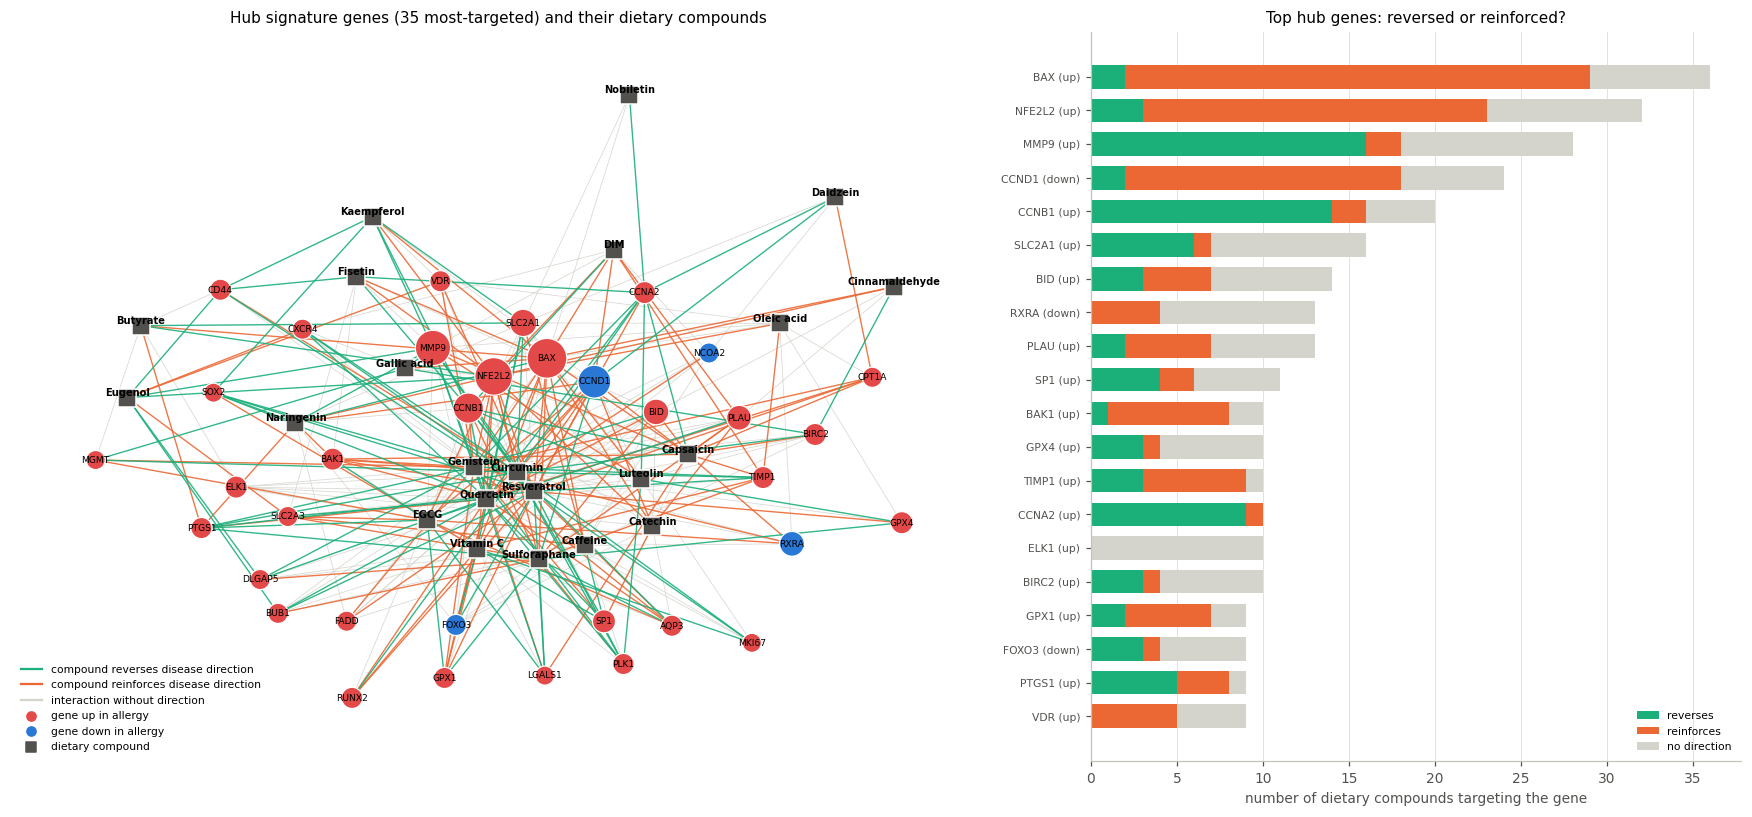

In [26]:
top_genes = list(deg_gene.index[:35])
top_comp = sorted({c for g in top_genes for c in B.neighbors(g)}, key=lambda c: -B.degree(c))[:22]
H = B.subgraph(top_genes + top_comp).copy()
pos = nx.spring_layout(H, seed=SEED, k=0.55, iterations=300)
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ecol = {"reverses": C_AQUA, "reinforces": C_ORANGE, "none": "#d4d3cc"}
for eff in ["none", "reinforces", "reverses"]:
    el = [(u, v) for u, v, e in H.edges(data="effect") if e == eff]
    nx.draw_networkx_edges(H, pos, edgelist=el, edge_color=ecol[eff], width=0.9 if eff != "none" else 0.5, ax=ax, alpha=0.9)
gn = [n for n in H if H.nodes[n]["kind"] == "gene"]
nx.draw_networkx_nodes(H, pos, nodelist=gn, node_size=[30 + 18 * B.degree(n) for n in gn],
                       node_color=[C_DIS if H.nodes[n]["dir"] > 0 else C_CTRL for n in gn], edgecolors="white", linewidths=0.8, ax=ax)
nx.draw_networkx_nodes(H, pos, nodelist=top_comp, node_shape="s", node_size=140, node_color="#52514e", edgecolors="white", ax=ax)
nx.draw_networkx_labels(H, pos, labels={n: n for n in gn}, font_size=6, ax=ax)
nx.draw_networkx_labels(H, pos, labels={c: BIOACTIVES[c][0].split(" (")[0] for c in top_comp}, font_size=6.5,
                        font_weight="bold", ax=ax, verticalalignment="bottom")
ax.plot([], [], color=C_AQUA, label="compound reverses disease direction"); ax.plot([], [], color=C_ORANGE, label="compound reinforces disease direction")
ax.plot([], [], color="#d4d3cc", label="interaction without direction")
ax.scatter([], [], c=C_DIS, label="gene up in allergy"); ax.scatter([], [], c=C_CTRL, label="gene down in allergy")
ax.scatter([], [], c="#52514e", marker="s", label="dietary compound")
ax.legend(fontsize=7, loc="lower left"); ax.axis("off")
ax.set_title("Hub signature genes (35 most-targeted) and their dietary compounds")
ax = axes[1]
hh = hubs.head(20).iloc[::-1]
yy = np.arange(len(hh))
ax.barh(yy, hh.reverses, color=C_AQUA, height=0.7, label="reverses")
ax.barh(yy, hh.reinforces, left=hh.reverses, color=C_ORANGE, height=0.7, label="reinforces")
ax.barh(yy, hh.none, left=hh.reverses + hh.reinforces, color="#d4d3cc", height=0.7, label="no direction")
ax.set_yticks(yy, [f"{g} ({d})" for g, d in zip(hh.index, hh.allergy_dir)], fontsize=7); ax.grid(axis="y", visible=False)
ax.set(xlabel="number of dietary compounds targeting the gene", title="Top hub genes: reversed or reinforced?")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
savefig(fig, "network_bioactives")

DASH["network"] = {
    "nodes": [{"id": n, "kind": H.nodes[n]["kind"], "label": BIOACTIVES[n][0] if n in BIOACTIVES else n,
               "dir": H.nodes[n].get("dir", 0), "degree": B.degree(n),
               "x": round(float(pos[n][0]), 4), "y": round(float(pos[n][1]), 4)} for n in H],
    "edges": [{"s": u, "t": v, "e": e} for u, v, e in H.edges(data="effect")],
    "hubs": hubs.head(30).reset_index(names="gene").to_dict(orient="records"),
    "communities": [[BIOACTIVES[c][0] for c in sorted(cs, key=lambda c: -B.degree(c))] for cs in communities],
}

**Interpretation.** About 70 % of the 1,177 signature genes (823) are targets of at least one of the 44 compounds,
which shows how saturated curated chemical data are. The hubs are not specific allergy genes but stress, apoptosis and
proliferation genes studied in cancer pharmacology: *BAX* (36 compounds), *NFE2L2/NRF2* (32), *MMP9*, *CCND1*, *CCNB1*.
Edge directions show what drives the null reversal result:
* Compounds **reverse** the proliferation and remodelling genes (*CCNB1*, *CCNA2*, *MMP9* are up in allergy and
  compounds decrease them, the usual anti-proliferative effect in tumour cells);
* but they **reinforce** *BAX*, *NFE2L2* and *CCND1*. *NFE2L2* (NRF2) is up in allergic tissue as an adaptive
  antioxidant response, and dietary electrophiles (sulforaphane, curcumin, quercetin) activate it further. That
  "reinforcement" is probably **beneficial**, which exposes a flaw in the simple reversal hypothesis (H3): not every
  change in disease tissue is pathogenic, some are compensatory.

The compound projection forms three communities that follow **how heavily each compound has been studied**, not its
chemistry: one holds the "big five" (quercetin, resveratrol, genistein, EGCG, caffeine) with curcumin, sulforaphane
and vitamin C; one holds mostly lipids, carotenoids and vitamins (DHA, EPA, vitamin D3, lycopene, α-tocopherol) with
small, metabolic target sets; the third holds the remaining flavonoids and spice compounds.

### 6d. Literature comparison
* **Sulforaphane** (the single positive finding) activates NRF2 and phase-II antioxidant genes in human upper-airway
  cells (Riedl et al., *Clin Immunol* 2009). In a small human trial, broccoli-sprout sulforaphane reduced the nasal
  allergic inflammatory response to diesel particles (Heber et al., *Food Funct* 2014). Our result is consistent with
  – but much weaker than – this literature: a modest 1.27-fold, degree-adjusted overlap, with no net reversal.
* **Curcumin** and **EGCG** show the highest (non-significant) reversal; small trials report symptom benefit of
  curcumin in allergic rhinitis (Wu & Xiao, *Eur Arch Otorhinolaryngol* 2016). Worth a targeted follow-up.
* **Vitamin D** and **omega-3 fatty acids** have the largest clinical trials in asthma/allergy prevention (e.g. VIDA,
  Castro et al. *JAMA* 2014, no benefit for treatment failure; fish oil in pregnancy and childhood wheeze, Bisgaard et
  al. *NEJM* 2016). Their CTD target sets are small and not enriched here – their proposed effects are systemic
  (immune development, receptor signalling) rather than direct transcriptional effects in the tissue, which a
  target-overlap analysis cannot capture.
* **Quercetin** is widely promoted as an anti-allergic mast-cell stabiliser, mainly from cell and animal studies. In
  curated human gene data we find no enrichment and no reversal, a reminder that *in vitro* mechanistic claims do not
  translate automatically to the disease transcriptome.

## Stage 7 – Machine learning (O4, H4)

**Task:** classify each sample as allergic vs healthy from its expression profile.

**Feature sets** (all defined *without* the labels of the data being predicted, to avoid leakage):

| Feature set | Definition |
|---|---|
| **Bioactive hub targets** | genes targeted by ≥ 4 of the 44 dietary bioactives in CTD – pure prior knowledge, no expression data used |
| **Bioactive-targeted signature (LOO)** | consensus signature re-derived from the *other six* contrasts, restricted to genes targeted by ≥ 1 bioactive |
| **Random genes (baseline)** | 15 random gene sets of the same size as each set above, drawn from the same dataset |
| **All genes + in-fold selection** | all expressed genes; the 100 most significant (ANOVA F) are chosen *inside* each training fold |
| **Majority class (baseline)** | `DummyClassifier` – AUROC 0.5 by construction |

**Model:** standardise → L2-regularised logistic regression (C = 0.1, class-balanced weights); a random forest (300 trees)
is also fitted on the hub-target set. **Evaluation:** repeated stratified k-fold CV (k = 5, or fewer when the minority
class is small; 5 repeats), AUROC and balanced accuracy. Significance against chance: label-permutation test (100
permutations). **Generalisation:** leave-one-dataset-out (LODO) – train on six contrasts, test on the seventh, with
genes z-scored within each dataset to remove platform effects.

In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, permutation_test_score
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore", category=UserWarning)

n_bio_per_gene = pd.Series(Counter(U[i] for c in BIOACTIVES for i in chem_targets_U[c]))
HUB = set(n_bio_per_gene.index[n_bio_per_gene >= 4])
print(f"bioactive hub targets (≥4 compounds): {len(HUB)} genes")

def lr():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))

def cv_for(y, repeats=5):
    k = int(min(5, np.bincount(y).min()))
    return RepeatedStratifiedKFold(n_splits=k, n_repeats=repeats, random_state=SEED)

def cv_auc(model, X, y, repeats=5):
    r = cross_validate(model, X, y, cv=cv_for(y, repeats), scoring=["roc_auc", "balanced_accuracy"])
    return r["test_roc_auc"].mean(), r["test_roc_auc"].std(), r["test_balanced_accuracy"].mean()

N_RAND = 15
RAND_LABEL = {"Bioactive hub targets": "Random genes (same size as hub set)",
              "Bioactive-targeted signature (LOO)": "Random genes (same size as signature set)"}
loo_sig = {}
ml_rows, rand_dist = [], {}
for name, d in datasets.items():
    x = d["expr"]; y = d["label"].loc[x.columns].values
    others = [n for n in DSN if n != name]
    m_loo, _ = consensus(others)
    sig_loo = m_loo[m_loo.signature]
    loo_sig[name] = sig_loo
    bio_any = set(n_bio_per_gene.index)
    fsets = {"Bioactive hub targets": sorted(HUB & set(x.index)),
             "Bioactive-targeted signature (LOO)": sorted(set(sig_loo.index) & bio_any & set(x.index))}
    res = {}
    for fs, genes in fsets.items():
        auc, sd, bacc = cv_auc(lr(), x.loc[genes].T.values, y)
        res[fs] = (auc, sd, bacc, len(genes))
        pool = np.array(x.index)
        aucs = [cv_auc(lr(), x.loc[rng.choice(pool, len(genes), replace=False)].T.values, y, repeats=2)[0] for _ in range(N_RAND)]
        rand_dist[(name, fs)] = aucs
        res[RAND_LABEL[fs]] = (np.mean(aucs), np.std(aucs), np.nan, len(genes))
    Xh = x.loc[fsets["Bioactive hub targets"]].T.values
    auc, sd, bacc = cv_auc(RandomForestClassifier(300, class_weight="balanced", random_state=SEED, n_jobs=-1), Xh, y, repeats=2)
    res["Bioactive hub targets – random forest"] = (auc, sd, bacc, Xh.shape[1])
    auc, sd, bacc = cv_auc(make_pipeline(StandardScaler(), SelectKBest(f_classif, k=100),
                                         LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)), x.T.values, y)
    res["All genes + in-fold top-100"] = (auc, sd, bacc, x.shape[0])
    auc, sd, bacc = cv_auc(DummyClassifier(strategy="prior"), Xh, y)
    res["Majority class"] = (auc, sd, bacc, 0)
    _, _, p_perm = permutation_test_score(lr(), Xh, y, cv=StratifiedKFold(int(min(5, np.bincount(y).min())), shuffle=True,
                                          random_state=SEED), scoring="roc_auc", n_permutations=100, random_state=SEED)
    for fs, (auc, sd, bacc, ng) in res.items():
        pct = (float((np.array(rand_dist[(name, fs)]) < auc).mean() * 100) if (name, fs) in rand_dist else np.nan)
        ml_rows.append({"dataset": name, "features": fs, "n_genes": ng, "AUROC": auc, "AUROC_sd": sd, "balanced_acc": bacc,
                        "perm_p": p_perm if fs == "Bioactive hub targets" else np.nan, "pct_beats_random": pct})
    print(f"{name:28s} hub AUROC {res['Bioactive hub targets'][0]:.3f} | random {np.mean(rand_dist[(name, 'Bioactive hub targets')]):.3f} "
          f"| sig-LOO {res['Bioactive-targeted signature (LOO)'][0]:.3f} | all-genes {res['All genes + in-fold top-100'][0]:.3f} | perm p {p_perm:.3f}")
ml = pd.DataFrame(ml_rows)
ml.to_csv(RES / "ml_within_dataset.csv", index=False)
hub_rows = ml[ml.features == "Bioactive hub targets"].set_index("dataset")
print(f"\nhub targets beat a random draw of equal size in {hub_rows.pct_beats_random.mean():.0f}% of comparisons on average"
      " (50% = no better than random)")
ml.pivot(index="dataset", columns="features", values="AUROC").reindex(DSN).round(3)

bioactive hub targets (≥4 compounds): 1013 genes


/tmp/ipykernel_128544/3132202112.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  zs, lfc, sig = zs[keep], lfc[keep], sig[keep].fillna(False)


AR/asthma nasal (child)      hub AUROC 0.825 | random 0.791 | sig-LOO 0.829 | all-genes 0.887 | perm p 0.020


/tmp/ipykernel_128544/3132202112.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  zs, lfc, sig = zs[keep], lfc[keep], sig[keep].fillna(False)


Asthma nasal                 hub AUROC 0.913 | random 0.899 | sig-LOO 0.940 | all-genes 0.909 | perm p 0.010


/tmp/ipykernel_128544/3132202112.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  zs, lfc, sig = zs[keep], lfc[keep], sig[keep].fillna(False)


... (6 outputs left out)

CRSwNP polyp (RNA-seq)       hub AUROC 0.988 | random 0.985 | sig-LOO 0.993 | all-genes 0.983 | perm p 0.010


/tmp/ipykernel_128544/3132202112.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  zs, lfc, sig = zs[keep], lfc[keep], sig[keep].fillna(False)


Eosinophilic oesophagitis    hub AUROC 1.000 | random 1.000 | sig-LOO 1.000 | all-genes 1.000 | perm p 0.010

hub targets beat a random draw of equal size in 50% of comparisons on average (50% = no better than random)


features,All genes + in-fold top-100,Bioactive hub targets,Bioactive hub targets – random forest,Bioactive-targeted signature (LOO),Majority class,Random genes (same size as hub set),Random genes (same size as signature set)
dataset,,,,,,,
AR/asthma nasal (child),0.887,0.825,0.798,0.829,0.5,0.791,0.798
Asthma nasal,0.909,0.913,0.884,0.940,0.5,0.899,0.896
Asthma bronchial,0.871,0.902,0.928,0.901,0.5,0.902,0.908
CRSwNP polyp (array),1.000,1.000,1.000,1.000,0.5,1.000,1.000
Atopic dermatitis skin,1.000,1.000,1.000,1.000,0.5,0.953,0.947
CRSwNP polyp (RNA-seq),0.983,0.988,0.968,0.993,0.5,0.985,0.982
Eosinophilic oesophagitis,1.000,1.000,1.000,1.000,0.5,1.000,1.000


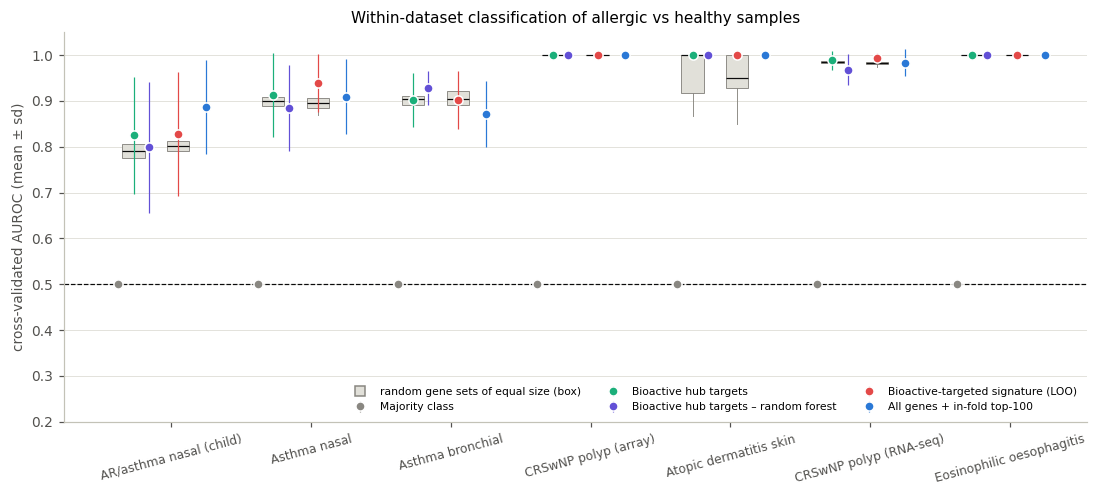

In [28]:
FS_ORDER = ["Majority class", "Bioactive hub targets", "Bioactive hub targets – random forest",
            "Bioactive-targeted signature (LOO)", "All genes + in-fold top-100"]
FS_COL = {"Majority class": C_MUTED, "Bioactive hub targets": C_AQUA, "Bioactive hub targets – random forest": C_VIOLET,
          "Bioactive-targeted signature (LOO)": C_DIS, "All genes + in-fold top-100": C_CTRL}
fig, ax = plt.subplots(figsize=(12, 4.6))
xs = np.arange(len(DSN))
for i, name in enumerate(DSN):
    rd = rand_dist[(name, "Bioactive hub targets")]
    ax.boxplot([rd], positions=[i - 0.27], widths=0.16, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#e1e0d9", edgecolor=C_MUTED, lw=0.6), medianprops=dict(color=C_INK, lw=0.8),
               whiskerprops=dict(color=C_MUTED, lw=0.6), capprops=dict(lw=0))
    rd2 = rand_dist[(name, "Bioactive-targeted signature (LOO)")]
    ax.boxplot([rd2], positions=[i + 0.05], widths=0.16, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#e1e0d9", edgecolor=C_MUTED, lw=0.6), medianprops=dict(color=C_INK, lw=0.8),
               whiskerprops=dict(color=C_MUTED, lw=0.6), capprops=dict(lw=0))
for j, fs in enumerate(FS_ORDER):
    sub = ml[ml.features == fs].set_index("dataset").reindex(DSN)
    off = {"Majority class": -0.38, "Bioactive hub targets": -0.27, "Bioactive hub targets – random forest": -0.16,
           "Bioactive-targeted signature (LOO)": 0.05, "All genes + in-fold top-100": 0.25}[fs]
    ax.errorbar(xs + off, sub.AUROC, yerr=sub.AUROC_sd, fmt="o", ms=6, color=FS_COL[fs], ecolor=FS_COL[fs], elinewidth=0.8,
                capsize=0, label=fs, markeredgecolor="white", zorder=4)
ax.plot([], [], marker="s", ls="", color="#e1e0d9", markeredgecolor=C_MUTED, label="random gene sets of equal size (box)")
ax.axhline(0.5, color=C_INK, lw=0.8, ls="--")
ax.set_xticks(xs, DSN, rotation=15, fontsize=8); ax.grid(axis="x", visible=False); ax.set_ylim(0.2, 1.05)
ax.set(ylabel="cross-validated AUROC (mean ± sd)", title="Within-dataset classification of allergic vs healthy samples")
ax.legend(fontsize=7, ncol=3, loc="lower right")
savefig(fig, "ml_within_dataset")

**Interpretation (within-dataset).**
Every feature set beats the majority baseline (AUROC 0.5) by a wide margin: ≈ 0.82–0.94 in the epithelial-brushing
studies and ≈ 0.98–1.00 in inflamed tissue (AD skin, polyps, EoE). The label-permutation test confirms this is not
chance (p ≤ 0.02 everywhere except the 12-sample CRSwNP array study, p ≈ 0.08, where the possible p-values are limited
by the sample size). The key comparison for H4 is with **random gene sets of the same size**: bioactive hub targets
beat a random draw in exactly **50 %** of comparisons on average, i.e. they are **no better than random genes**. When a
disease changes hundreds to thousands of genes, almost any thousand genes carry enough signal to separate the groups,
so "bioactive target genes predict allergy" says nothing specific about the compounds. The leave-one-out signature (derived
from *other* studies) is the best or joint-best feature set in 5/7 datasets, so the consensus signature generalises.
Childhood nasal epithelium (GSE19187) is the hardest dataset, consistent with its weak disease signal in the PCA.

In [29]:
common = sorted(set.intersection(*[set(d["expr"].index) for d in datasets.values()]))
Z = {n: d["expr"].loc[common].sub(d["expr"].loc[common].mean(axis=1), axis=0)
         .div(d["expr"].loc[common].std(axis=1).replace(0, 1), axis=0) for n, d in datasets.items()}
Y = {n: d["label"].loc[d["expr"].columns].values for n, d in datasets.items()}
hub_c = [g for g in common if g in HUB]
print(f"genes measured in all 7 contrasts: {len(common)}; of which bioactive hub targets: {len(hub_c)}")

def lodo_auc(genes):
    out = {}
    for test in DSN:
        tr = [n for n in DSN if n != test]
        Xtr = np.vstack([Z[n].loc[genes].T.values for n in tr]); ytr = np.concatenate([Y[n] for n in tr])
        m = lr().fit(Xtr, ytr)
        out[test] = roc_auc_score(Y[test], m.predict_proba(Z[test].loc[genes].T.values)[:, 1])
    return out

lodo_hub = lodo_auc(hub_c)
lodo_rand = [lodo_auc(list(rng.choice(common, len(hub_c), replace=False))) for _ in range(N_RAND)]
lodo_score, lodo_score_bio = {}, {}
for test in DSN:
    sl = loo_sig[test]
    up = [g for g in sl.index[sl.dir > 0] if g in Z[test].index]
    dn = [g for g in sl.index[sl.dir < 0] if g in Z[test].index]
    sc = Z[test].loc[up].mean() - (Z[test].loc[dn].mean() if dn else 0)
    lodo_score[test] = roc_auc_score(Y[test], sc)
    upb, dnb = [g for g in up if g in n_bio_per_gene.index], [g for g in dn if g in n_bio_per_gene.index]
    scb = Z[test].loc[upb].mean() - (Z[test].loc[dnb].mean() if dnb else 0)
    lodo_score_bio[test] = roc_auc_score(Y[test], scb)
lodo = pd.DataFrame({"LR on bioactive hub targets": lodo_hub,
                     "LR on random genes (mean)": pd.DataFrame(lodo_rand).mean(),
                     "LR on random genes (sd)": pd.DataFrame(lodo_rand).std(),
                     "Signature score (LOO, no training)": lodo_score,
                     "Bioactive-targeted signature score (LOO)": lodo_score_bio}).loc[DSN]
lodo.loc["mean"] = lodo.mean()
lodo.to_csv(RES / "ml_leave_one_dataset_out.csv")
stab = pd.DataFrame({t: {"signature genes": len(sl), "Jaccard with full signature": len(set(sl.index) & set(SIG.index)) /
                         len(set(sl.index) | set(SIG.index))} for t, sl in loo_sig.items()}).T
print("stability of the consensus signature when each contrast is left out:")
print(stab.round(2).to_string())
rand_means = pd.DataFrame(lodo_rand).mean(axis=1)
lodo_p = (1 + (rand_means >= lodo.loc["mean", "LR on bioactive hub targets"]).sum()) / (len(rand_means) + 1)
print(f"mean LODO AUROC: hub targets {lodo.loc['mean', 'LR on bioactive hub targets']:.3f} vs random-gene draws "
      f"{rand_means.mean():.3f} (range {rand_means.min():.3f}–{rand_means.max():.3f}); empirical p = {lodo_p:.2f}")
lodo.round(3)

genes measured in all 7 contrasts: 5964; of which bioactive hub targets: 642


stability of the consensus signature when each contrast is left out:
                           signature genes  Jaccard with full signature
AR/asthma nasal (child)             1273.0                         0.64
Asthma nasal                        1340.0                         0.65
Asthma bronchial                    1097.0                         0.57
CRSwNP polyp (array)                1095.0                         0.69
Atopic dermatitis skin              1000.0                         0.52
CRSwNP polyp (RNA-seq)               788.0                         0.39
Eosinophilic oesophagitis            856.0                         0.44
mean LODO AUROC: hub targets 0.841 vs random-gene draws 0.825 (range 0.769–0.865); empirical p = 0.38


,LR on bioactive hub targets,LR on random genes (mean),LR on random genes (sd),"Signature score (LOO, no training)",Bioactive-targeted signature score (LOO)
AR/asthma nasal (child),0.751,0.665,0.080,0.707,0.700
Asthma nasal,0.892,0.909,0.028,0.633,0.644
Asthma bronchial,0.805,0.848,0.026,0.701,0.708
CRSwNP polyp (array),0.750,0.891,0.086,1.000,1.000
Atopic dermatitis skin,0.948,0.750,0.155,0.781,0.802
CRSwNP polyp (RNA-seq),0.773,0.816,0.059,0.858,0.866
Eosinophilic oesophagitis,0.967,0.898,0.134,0.917,0.917
mean,0.841,0.825,0.081,0.799,0.805


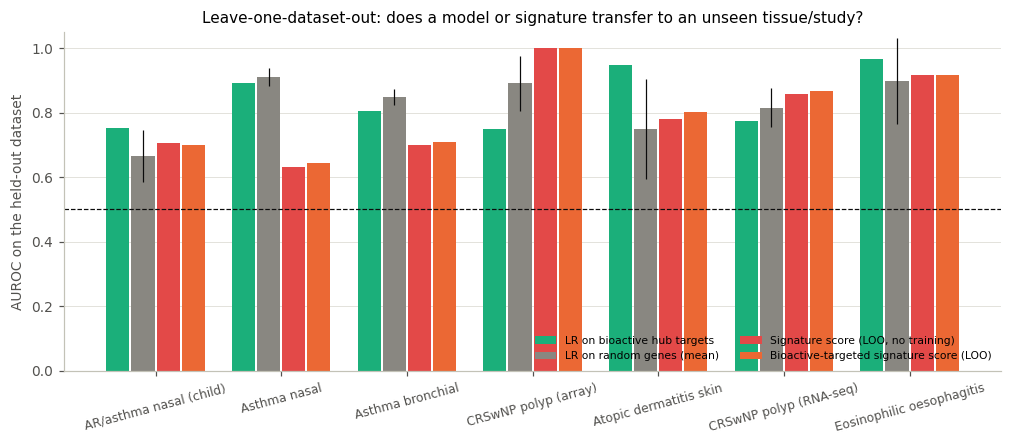

In [30]:
fig, ax = plt.subplots(figsize=(11, 4))
cols = [("LR on bioactive hub targets", C_AQUA), ("LR on random genes (mean)", C_MUTED),
        ("Signature score (LOO, no training)", C_DIS), ("Bioactive-targeted signature score (LOO)", C_ORANGE)]
w = 0.2
for j, (c, colr) in enumerate(cols):
    vals = lodo.loc[DSN, c]
    err = lodo.loc[DSN, "LR on random genes (sd)"] if "random" in c else None
    ax.bar(np.arange(len(DSN)) + (j - 1.5) * w, vals, w * 0.92, color=colr, label=c, yerr=err,
           error_kw=dict(elinewidth=0.8, ecolor=C_INK))
ax.axhline(0.5, color=C_INK, lw=0.8, ls="--")
ax.set_xticks(np.arange(len(DSN)), DSN, rotation=15, fontsize=8); ax.grid(axis="x", visible=False); ax.set_ylim(0, 1.05)
ax.set(ylabel="AUROC on the held-out dataset", title="Leave-one-dataset-out: does a model or signature transfer to an unseen tissue/study?")
ax.legend(fontsize=7, ncol=2, loc="lower right")
savefig(fig, "ml_lodo")

DASH["ml"] = {"within": ml.round(4).replace({np.nan: None}).to_dict(orient="records"),
              "random": {f"{k[0]}||{k[1]}": [round(v, 4) for v in vals] for k, vals in rand_dist.items()},
              "lodo": lodo.round(4).reset_index(names="dataset").to_dict(orient="records"),
              "n_hub": len(HUB), "n_common": len(common), "n_hub_common": len(hub_c), "lodo_p": float(lodo_p),
              "lodo_rand_means": rand_means.round(4).tolist(), "stability": stab.round(3).reset_index(names="left_out").to_dict(orient="records")}

**Interpretation (cross-dataset).** Transfer to an unseen study, tissue and platform is the harder and more honest test.
A logistic regression on the 642 bioactive hub targets, trained on six contrasts, reaches a mean held-out AUROC of
≈ 0.84, but random gene sets of the same size reach ≈ 0.83 (empirical p ≈ 0.38). Again, the bioactive prior adds
nothing. The **signature score** (mean of up-genes minus down-genes from the other six studies; *nothing fitted*)
reaches ≈ 0.80 and is perfect or near-perfect for polyps and EoE. This is direct evidence that a **shared
cross-tissue allergy signature exists**, although it transfers less well to adult asthmatic nasal brushings
(≈ 0.63). Restricting the signature to bioactive-targeted genes changes nothing (≈ 0.81). **H4 is therefore only
partly supported:** bioactive targets classify disease far better than the majority baseline, but no better than
equally many random genes, within or across datasets.

## Stage 8 – Conclusions

**Research question:** *Are genes consistently dysregulated across human allergic tissues over-represented among the
curated targets of dietary bioactives beyond study bias, and do these compounds oppose the disease direction?*

**Answer: essentially no.** A robust, reproducible cross-tissue allergy signature exists, but the curated targets
of 44 common dietary bioactives are not specially enriched in it once gene study-bias is controlled, are no more
enriched than those of ordinary non-dietary chemicals, and are not preferentially moved in the anti-disease
direction. The one exception (sulforaphane) is modest and partly reflects its history as an anti-cancer compound.

| Objective | Result | Hypothesis |
|---|---|---|
| **O1 – signature** | 7 contrasts (5 tissues, 291 samples) → 1,177-gene consensus signature (860 up, 317 down), anchored by type-2 / mast-cell genes (*CPA3*, *CDH26*, *POSTN*, *CCL26*, *ALOX15*, *SERPINB4*), replicated in ≥ 2 studies each; a signature learned on 6 studies separates cases from controls in the 7th without any training. | – |
| **O2 – enrichment & direction** | Naive test: 8/44 bioactives "enriched" (and 20 % of all CTD chemicals). Degree-matched: 1/44 (sulforaphane, 1.27×, FDR ≈ 0.03). Dietary vs other chemicals: no difference (p ≈ 0.75). Reversal: 47 % vs 50 % expected, 0/14 compounds significant. | H1 not supported (one exception); H2 not supported; H3 not supported |
| **O3 – interpretation** | Up: interleukin signalling, immunoregulatory interactions, granulocyte degranulation, mitotic cell cycle. Down: de novo ceramide/sphingolipid synthesis, sterol / nuclear-receptor metabolism (barrier link). Network hubs are generic stress/proliferation genes (*BAX*, *NFE2L2*, *MMP9*, *CCNB1*); compounds reverse proliferation genes but reinforce *NFE2L2* (likely a protective response). CTD curated allergy genes were *not* enriched (they are mostly susceptibility loci). | – |
| **O4 – prediction** | Bioactive hub targets classify disease well above the majority baseline (AUROC 0.82–1.00 within datasets; 0.84 across datasets), but no better than random gene sets of equal size (50th percentile within; 0.83, p ≈ 0.38 across). An untrained signature score from 6 studies reaches AUROC ≈ 0.80 on the 7th. | H4 partly supported |

**Limitations**
* **Curated knowledge ≠ biology.** CTD reflects what has been studied: interactions come mostly from cancer cell lines
  and high doses, and are dominated by a few compounds (quercetin, resveratrol). Absence of enrichment is not proof of
  no effect, and dose, bioavailability and metabolism (e.g. quercetin is poorly absorbed) are ignored.
* **The reversal hypothesis is simplistic.** Some disease changes are compensatory (NRF2), so "reinforcing" a change is
  not necessarily harmful.
* **Heterogeneous, small and imperfect data.** Different tissues, platforms and ages (children vs adults); two
  studies with ≤ 16 samples; GSE41861 nasal and bronchial samples share subjects (not independent in the
  meta-analysis) and their deposited values had the sex signal removed; one GSE19187 sex annotation is inconsistent;
  GSE36830 needed log-transformation. Bulk tissue mixes cell types, so part of the signature reflects cell
  composition (immune infiltrate) rather than per-cell regulation.
* **Methods.** The limma-style moderated t was re-implemented in Python and the Stouffer meta-analysis assumes
  independence; the consensus thresholds are a choice. Leaving out one contrast changes the signature noticeably (see the stability
  table in Stage 7), especially when a large, strongly inflamed study (polyps RNA-seq, EoE, AD) is removed, so individual
  signature genes should be read as "replicated in several tissues", not as a definitive list.
* **Machine learning** is on small samples; within-dataset CV is optimistic for tiny studies, and cross-dataset z-scoring
  uses the (unlabelled) test-set mean and variance.

**Future steps**
1. Use *perturbational* data instead of curated literature: human cells treated with these compounds at realistic
   doses (e.g. LINCS L1000 / CMap, GEO treatment series) to compute signature reversal directly.
2. Focus on the leads that survived or came closest (sulforaphane, curcumin, EGCG) with cell-type-resolved data
   (single-cell airway and skin atlases) to separate epithelial from immune effects.
3. Add a dietary-exposure arm: link FooDB food composition or cohort nutrition data to allergy outcomes, and test
   the ceramide / sphingolipid barrier axis, which emerged here as a biologically coherent target.
4. Use random-effects meta-analysis with subject-level pairing for GSE41861 and protein-interaction context (STRING)
   to prioritise signature hubs that are not merely well-studied.

In [31]:
DASH["datasets"] = summary.assign(**{"allergic": [int(datasets[k]["label"].sum()) for k in summary.dataset],
                                     "healthy": [int((datasets[k]["label"] == 0).sum()) for k in summary.dataset]}).to_dict(orient="records")
DASH["qc"] = qc_table.replace({np.nan: None}).to_dict(orient="records")
DASH["sex"] = sex_table.replace({np.nan: None}).to_dict(orient="records")
DASH["bioactives"] = [{"ctd": k, "name": v[0], "class": v[1], "n_targets_ctd": int(bio_targets[k])} for k, v in BIOACTIVES.items()]
DASH["n_samples"] = int(sum(len(d["label"]) for d in datasets.values()))

def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o

with open(RES / "dashboard_data.json", "w") as fh:
    json.dump(_clean(DASH), fh, separators=(",", ":"))
print("saved", RES / "dashboard_data.json", f"({(RES / 'dashboard_data.json').stat().st_size / 1e6:.2f} MB)")
print("figures:", ", ".join(sorted(p.stem for p in FIG.glob('*.png'))))

saved /home/mugo/Projects/DietaryBioactivesAndAllergy/results/dashboard_data.json (0.56 MB)
figures: consensus_heatmap, consensus_replication, de_positive_controls, de_volcanoes, eda_ctd, eda_distributions, eda_pca, eda_sample_counts, enrichment_bioactives, ml_lodo, ml_within_dataset, network_bioactives, qc_sex_check, qc_tissue_markers, reactome_enrichment, reversal_bioactives
